# Culver City and Beverly Hills rent registries — cleaning & first look

This notebook combines two different public-records structures:

| jurisdiction / file | release | coverage | structure |
|---|---|---|---|
| Culver City / `Responsive Record #25-384.csv` | 2025 | rent dates through mid-2025 | longitudinal rent observations |
| Culver City / `26-962.csv` | 2026 | rent dates through 2026 | longitudinal rent observations; 24 columns |
| Beverly Hills / `unit_report.csv` | 2026 | current as of September 2026 | one current snapshot row per reported unit |

A Culver City row is **one dated rent observation for one unit**. A Beverly Hills row is **one current unit snapshot** with monthly rent, maximum allowable rent, move-in date and last-increase date. Cross-city comparisons therefore use one latest/current row per unit. Longitudinal sections remain Culver City-only unless explicitly stated.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 40)

DATA_DIR = Path("../../DATA/CULVERCITY")
BH_FILE = Path("../../DATA/BEVERLYHILLS/unit_report.csv")
FILES = {  # newest release first: it wins when the two disagree
    "26-962": DATA_DIR / "26-962.csv",
    "25-384": DATA_DIR / "Responsive Record #25-384.csv",
}

# plot style: thin marks, recessive axes
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Load

The two Culver City CSVs are raw exports with the same quirks:
- a UTF-8 BOM on the header;
- all-comma **separator rows** between properties (~30k in 26-962, ~28k in 25-384);
- padded whitespace (`"11408  WASHINGTON PL"`, `"1950 "`), `N/A` placeholders and empty strings;
- in 26-962 a duplicated `Year Built` column (pandas reads the second one as `Year Built.1`).

Everything is read as text first so nothing gets silently coerced. The Beverly Hills CSV is a normalized extraction from the 300-page unit-report PDF. Its three rows explicitly marked as test records are excluded, and one exact duplicate unit row is removed before analysis.

In [2]:
RENAME = {
    "Business Name [DBA]": "business_name",
    "Bus Address": "address",
    "Bus City, State": "city_state_zip",
    "Owner Name": "owner_name",
    "Number of Units": "n_units",
    "Unit Number": "unit_number",
    "Unit Status": "unit_status",
    "Bedrooms": "bedrooms",
    "Bathrooms": "bathrooms",
    "Year Built": "year_built",
    "Year Built.1": "year_built_2",
    "Occupancy Date": "occupancy_date",
    "Lease Start": "lease_start",
    "Lease End": "lease_end",
    "Encumbered Unit": "encumbered",
    "Services Included With Rent": "services_included",
    "Rent Date": "rent_date",
    "Rent Amount": "rent",
    "Utilities Paid by Landlord": "utilities_paid_by_landlord",
    "Certificate of Occupancy Date": "cert_occupancy_date",
    "Parcel": "parcel",
    "Total Number of Units": "total_units",
    "Total Number of Units PA": "total_units_pa",
    "Custom Field Rent Control": "rent_control",
}


def load_release(path, source):
    df = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
    n_raw = len(df)
    df = df.dropna(how="all")  # separator rows
    df = df.apply(lambda s: s.str.strip().str.replace(r"\s+", " ", regex=True))
    df = df.replace({"": np.nan, "N/A": np.nan}).rename(columns=RENAME)
    df["source"] = source
    df["file_row"] = np.arange(len(df))
    # The export lists a property as one contiguous block of rows. Some addresses
    # appear in two blocks (an older and a current registration record); tag them.
    df["block"] = source + "_" + df["address"].ne(df["address"].shift()).cumsum().astype(str)
    print(f"{source}: {n_raw:>6,} raw rows -> {len(df):>6,} after dropping separator rows, {df.shape[1] - 3} columns")
    return df.reset_index(drop=True)


raw = {src: load_release(path, src) for src, path in FILES.items()}

26-962: 80,082 raw rows -> 50,188 after dropping separator rows, 24 columns
25-384: 64,166 raw rows -> 36,260 after dropping separator rows, 19 columns


## 2. Clean

### Parse types
- `rent`: strip thousands separators and convert to float.
- Dates: month/day/year, with or without zero padding.
- `year_built` of 0, or before 1850 (typos like 1650), is set to missing. Bedroom counts above 8 (e.g. 20, 30, 33) are building totals typed into the unit field, so they're also set to missing.
- `Yes/No` and `True/False` columns become booleans. Address, unit and owner text is uppercased.

In [3]:
def parse_types(df):
    df = df.copy()
    df["rent"] = pd.to_numeric(df["rent"].str.replace(",", ""), errors="coerce")
    for c in ["rent_date", "lease_start", "lease_end", "occupancy_date", "cert_occupancy_date"]:
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed", errors="coerce")
    for c in ["n_units", "bedrooms", "year_built", "year_built_2", "total_units"]:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
    df["bathrooms"] = pd.to_numeric(df["bathrooms"], errors="coerce")
    df["year_built"] = df["year_built"].mask((df["year_built"] == 0) | (df["year_built"] < 1850))
    df["bedrooms"] = df["bedrooms"].mask(df["bedrooms"] > 8)
    df["encumbered"] = df["encumbered"].map({"True": True, "False": False})
    df["rent_control"] = df["rent_control"].map({"Yes": True, "No": False})
    for c in ["address", "unit_number", "owner_name", "business_name"]:
        df[c] = df[c].str.upper()
    return df


parsed = {src: parse_types(d) for src, d in raw.items()}
parsed["26-962"].dtypes.to_frame("dtype").T

,business_name,address,city_state_zip,owner_name,n_units,unit_number,unit_status,bedrooms,bathrooms,year_built,occupancy_date,lease_start,lease_end,encumbered,services_included,rent_date,rent,utilities_paid_by_landlord,year_built_2,cert_occupancy_date,parcel,total_units,total_units_pa,rent_control,source,file_row,block
dtype,object,object,object,object,Int64,object,object,Int64,float64,Int64,datetime64[ns],datetime64[ns],datetime64[ns],bool,object,datetime64[ns],float64,object,Int64,datetime64[ns],object,Int64,object,bool,object,int64,object


### Combine the two releases

26-962 is nearly a superset of 25-384, so it is the base. I add 25-384 records only when their (address, unit, rent date) key is missing from 26-962. Most of those are properties that dropped out of the later release.

Rent-control flag: 25-384 marks only ~560 rows as rent-controlled, while 26-962 marks ~14.7k. The flag was clearly updated between releases, and it also differs between a unit's old and current registration blocks. So each unit gets the flag from its **most current** registration (set after deduplication, below).

In [4]:
KEY = ["address", "unit_number", "rent_date"]
new, old = parsed["26-962"], parsed["25-384"]


def key_of(d):
    return d[KEY].astype(str).agg("|".join, axis=1)


in_new = key_of(old).isin(set(key_of(new)))
old_only = old[~in_new]
print(f"25-384 rows also in 26-962: {in_new.mean():.1%}")
print(f"25-384 rows added: {len(old_only):,}  "
      f"({old_only['address'].nunique()} addresses, "
      f"{(~old_only['address'].isin(set(new['address']))).sum()} rows from addresses absent in 26-962)")

combined = pd.concat([new, old_only], ignore_index=True)
print(f"combined: {len(combined):,} rows")

25-384 rows also in 26-962: 99.0%
25-384 rows added: 378  (89 addresses, 160 rows from addresses absent in 26-962)
combined: 50,566 rows


### Deduplicate

There are two sources of duplicate rows:
1. **Exact duplicates**: identical rows, apart from row position.
2. **The same unit and rent date listed twice.** This happens when an address has both an old and a current registration block, and it mostly hits the 6/11/2019 base-rent date. Example: *4039 Lincoln Ave* has an old block covering 2019–20 with rent-control = No, and a current block covering 2019–26 with rent-control = Yes. The two blocks disagree on the 2019 base rent. The 230 duplicated 6/20/2025 rows at *8770 Washington Blvd* are the same issue.

   Tie-break: keep a **nonzero** rent first, then the row from the **most current block** (the block with the latest rent date).

Rows with **no rent date** are kept separately in `no_rent`. They are properties with zero units or units that never reported a rent, mostly owner-occupied or exempt. They count toward registered addresses but are not part of the rent panel.

In [5]:
n0 = len(combined)
combined = combined.drop_duplicates(subset=combined.columns.difference(["file_row", "block", "source"]))
print(f"exact duplicates dropped: {n0 - len(combined)}")

combined["block_last_date"] = combined.groupby("block")["rent_date"].transform("max")
has_date = combined["rent_date"].notna()
no_rent = combined[~has_date].copy()

df = (
    combined[has_date]
    .assign(_nonzero=lambda d: d["rent"].gt(0))
    .sort_values(["_nonzero", "block_last_date", "file_row"], ascending=False)
    .drop_duplicates(KEY, keep="first")
    .drop(columns="_nonzero")
    .sort_values(["address", "unit_number", "rent_date"])
    .reset_index(drop=True)
)
print(f"same unit + rent date duplicates dropped: {has_date.sum() - len(df):,}")
print(f"rent panel: {len(df):,} rows | rows without a rent date: {len(no_rent):,}")

exact duplicates dropped: 7
same unit + rent date duplicates dropped: 794
rent panel: 48,289 rows | rows without a rent date: 1,476


### Flag bad rents, add IDs

**Rent flags.** The raw `rent` column is kept unchanged. `rent_clean` is set to missing for:
- `zero`: rent = 0. These are mostly vacant or owner-occupied units, but about 1.9k are marked *Rented*.
- `below_min`: rent under $100, e.g. placeholder values like 1.00 or 0.01.
- `above_max`: rent over $20,000. Nearly all are **dates typed into the rent field**: `8,012,018` is 8/01/2018 and `9,152,017` is 9/15/2017. The rest look like misplaced decimals (`34,950` for a 2-bedroom). Rents between $10k and $20k are mostly 4–6-bedroom houses and are left in.

**Year window.** A handful of rent dates fall before 2019 (probably move-in dates) or are obvious typos such as 2027. They are excluded from the yearly analysis via `in_window` = 2019–2026. The registry starts at the 6/11/2019 base-rent date.

**IDs.**
- `owner`: `owner_name`, falling back to `business_name` when the owner is blank (~1.1k rows).
- `building`: the address with any `# / UNIT / APT / STE` suffix removed. Condos are registered one unit per address, so this groups them into buildings.
- `unit_id`: address + unit number.

In [6]:
RENT_MIN, RENT_MAX = 100, 20_000
UNIT_DESIGNATOR = r"\s+(#|UNIT|APT|STE|SPC)\b.*$"


def add_ids(d):
    d["owner"] = d["owner_name"].fillna(d["business_name"])
    d["building"] = d["address"].str.replace(UNIT_DESIGNATOR, "", regex=True)
    d["unit_id"] = d["address"] + " | " + d["unit_number"].fillna("")
    return d


df["rent_flag"] = np.select(
    [df["rent"].eq(0), df["rent"].lt(RENT_MIN), df["rent"].gt(RENT_MAX)],
    ["zero", "below_min", "above_max"],
    default="ok",
)
df["rent_clean"] = df["rent"].where(df["rent_flag"].eq("ok"))
df["year"] = df["rent_date"].dt.year
df["in_window"] = df["year"].between(2019, 2026)
df, no_rent = add_ids(df), add_ids(no_rent)

# carry each unit's rent-control flag from its most current registration to all its rows
current_flag = df.sort_values(["block_last_date", "rent_date"]).groupby("unit_id")["rent_control"].last()
df["rent_control"] = df["unit_id"].map(current_flag)

display(pd.crosstab(df["rent_flag"], df["unit_status"].fillna("(blank)"), margins=True))
print(f"rent dates outside 2019-2026: {(~df['in_window']).sum()}")
df.loc[df["rent_flag"].eq("above_max"), ["address", "unit_number", "bedrooms", "rent_date", "rent"]].sort_values("rent").tail(8)

unit_status,Owner Occupied,Rented,Vacant,All
rent_flag,,,,
above_max,1,108,4,113
below_min,3,45,8,56
ok,182,43170,1992,45344
zero,191,1681,904,2776
All,377,45004,2908,48289


rent dates outside 2019-2026: 20


,address,unit_number,bedrooms,rent_date,rent
27288,4214 IRVING PL,A,1,2019-06-11,9182023.0
2037,10878 VENICE BLVD,G5,1,2019-06-11,10012011.0
7258,12305 WASHINGTON PL,A,2,2019-06-11,10152019.0
13974,3852 COLLEGE AVE,3,1,2019-06-11,10152019.0
9818,3330 CAROLINE AVE,D,1,2019-06-11,10242015.0
14024,3853 PROSPECT AVE,1,2,2019-06-11,11012019.0
2028,10878 VENICE BLVD,G4,1,2019-06-11,12082019.0
2073,10878 VENICE BLVD,V3,1,2019-06-11,12152016.0


### Beverly Hills snapshot

The Beverly Hills report is already unit-level, so it does not enter the Culver City release-combination logic above. The cleaning below excludes the three explicit test rows, removes one exact duplicate carried across two PDF pages, parses numeric and date fields, and creates comparable rent and unit identifiers. `last_rental_increase_date` is retained as an attribute; it is **not** treated as a dated rent observation.

In [7]:
bh_raw = pd.read_csv(BH_FILE, dtype=str, keep_default_na=False)
bh = bh_raw[bh_raw["is_test_record"].ne("true")].replace("", np.nan).copy()
bh_value_cols = bh.columns.difference(["source_page", "source_row"])
n_before = len(bh)
bh = bh.drop_duplicates(subset=bh_value_cols).reset_index(drop=True)

for c in ["year_built", "total_units", "monthly_rent", "maximum_allowable_rent",
          "original_rent_amount", "bathrooms", "bedrooms"]:
    bh[c] = pd.to_numeric(bh[c], errors="coerce")
for c in ["move_in_date", "last_rental_increase_date"]:
    bh[c] = pd.to_datetime(bh[c], errors="coerce")
for c in ["address", "unit", "property_owner"]:
    bh[c] = bh[c].str.upper()

bh["rent_flag"] = np.select(
    [bh["monthly_rent"].eq(0), bh["monthly_rent"].lt(RENT_MIN), bh["monthly_rent"].gt(RENT_MAX)],
    ["zero", "below_min", "above_max"], default="ok",
)
bh.loc[bh["monthly_rent"].isna(), "rent_flag"] = "missing"
bh["rent_clean"] = bh["monthly_rent"].where(bh["rent_flag"].eq("ok"))
bh["unit_id"] = bh["address"] + " | " + bh["unit"].fillna("")
bh["owner"] = bh["property_owner"]
bh["occupied"] = bh["is_unit_currently_occupied"].map({"Y": True, "N": False})

print(f"Beverly Hills: {len(bh_raw):,} extracted rows - "
      f"{bh_raw['is_test_record'].eq('true').sum()} test rows - {n_before - len(bh)} exact duplicate = {len(bh):,} analysis rows")
display(pd.crosstab(bh["rent_flag"], bh["rent_control_chapter"].fillna("(blank)"), margins=True))

Beverly Hills: 7,462 extracted rows - 3 test rows - 1 exact duplicate = 7,458 analysis rows


rent_control_chapter,(blank),Chapter 5,Chapter 6,All
rent_flag,,,,
above_max,0,0,1,1
missing,1100,1,5,1106
ok,0,110,6197,6307
zero,0,44,0,44
All,1100,155,6203,7458


## 3. Extent of the data

`panel` is the Culver City rent-history panel limited to 2019–2026. `cc_units` takes the latest observation for each Culver City unit; `bh` is the deduplicated Beverly Hills snapshot. The first table separates longitudinal coverage from the comparable current/latest unit cross-section.

In [8]:
panel = df[df["in_window"]].copy()
everything = pd.concat([df, no_rent])
cc_units = panel.sort_values(["rent_date", "block_last_date"]).groupby("unit_id").tail(1).copy()

culver_history = pd.Series({
    "rent observations": len(panel),
    "usable rent observations": panel["rent_clean"].notna().sum(),
    "years": f"{panel['year'].min()}–{panel['year'].max()} ({panel['year'].nunique()} years)",
    "rent date range": f"{panel['rent_date'].min():%Y-%m-%d} → {panel['rent_date'].max():%Y-%m-%d}",
}, name="Culver City history")
display(culver_history.to_frame())

extent = pd.DataFrame({
    "Culver City (latest per unit)": {
        "unit rows": len(cc_units),
        "with usable rent": cc_units["rent_clean"].notna().sum(),
        "addresses": cc_units["address"].nunique(),
        "buildings / properties": cc_units["building"].nunique(),
        "parcels with APN": cc_units["parcel"].nunique(),
        "owners": cc_units["owner"].nunique(),
    },
    "Beverly Hills (2026 snapshot)": {
        "unit rows": len(bh),
        "with usable rent": bh["rent_clean"].notna().sum(),
        "addresses": bh["address"].nunique(),
        "buildings / properties": bh["apn"].nunique(),
        "parcels with APN": bh["apn"].nunique(),
        "owners": bh["owner"].nunique(),
    },
})
extent.astype("Int64")

,Culver City history
rent observations,48269
usable rent observations,45324
years,2019–2026 (8 years)
rent date range,2019-01-01 → 2026-10-01


,Culver City (latest per unit),Beverly Hills (2026 snapshot)
unit rows,8414,7458
with usable rent,7911,6307
addresses,2896,2332
buildings / properties,2543,1091
parcels with APN,1987,1091
owners,2696,833


### Culver City rent records per year

Beverly Hills has no comparable rent-observation history, so this subsection remains Culver City-only. `units` is the number of distinct units with at least one rent record that year. `share_of_units` divides it by all Culver City units ever observed.

In [9]:
n_units_total = panel["unit_id"].nunique()
per_year = panel.groupby("year").agg(
    rent_records=("rent", "size"),
    units=("unit_id", "nunique"),
    addresses=("address", "nunique"),
    owners=("owner", "nunique"),
    median_rent=("rent_clean", "median"),
)
per_year["records_per_unit"] = (per_year["rent_records"] / per_year["units"]).round(2)
per_year["share_of_units"] = (per_year["units"] / n_units_total).round(2)
per_year

,rent_records,units,addresses,owners,median_rent,records_per_unit,share_of_units
year,,,,,,,
2019,8399,8238,2859,2679,2150.0,1.02,0.98
2020,4246,4124,1961,1794,2100.0,1.03,0.49
2021,2312,2148,744,687,2400.0,1.08,0.26
2022,7825,5137,1736,1586,2295.0,1.52,0.61
2023,5975,5658,1754,1591,2495.0,1.06,0.67
2024,6467,6355,2042,1849,2500.0,1.02,0.76
2025,6448,6354,2061,1882,2595.0,1.01,0.76
2026,6597,6431,2046,1868,2686.0,1.03,0.76


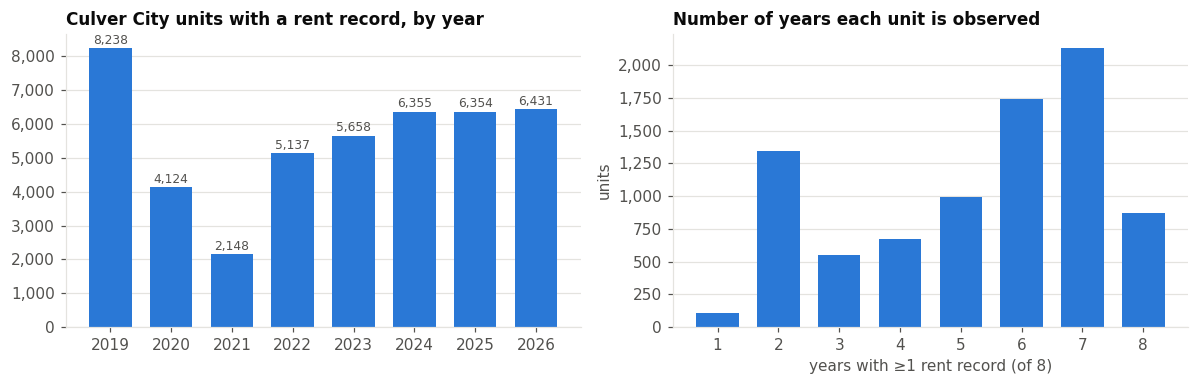

In [10]:
years_per_unit = panel.groupby("unit_id")["year"].nunique().value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

ax1.bar(per_year.index, per_year["units"], width=0.7, color=SERIES[0])
ax1.set_title("Culver City units with a rent record, by year")
ax1.set_xticks(per_year.index)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
for x, y in per_year["units"].items():
    ax1.annotate(f"{y:,}", (x, y), xytext=(0, 3), textcoords="offset points",
                 ha="center", fontsize=8, color=INK_2)

ax2.bar(years_per_unit.index, years_per_unit.values, width=0.7, color=SERIES[0])
ax2.set_title("Number of years each unit is observed")
ax2.set_xticks(years_per_unit.index)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax2.set_xlabel("years with ≥1 rent record (of 8)")
ax2.set_ylabel("units")

fig.tight_layout()

### How often is Culver City rent recorded within a year?

Mostly once per unit per year, at the annual registration in June–July. The exception is 2022, which averages 1.5 records per unit. That is because ~800 records carry a 1/1/2022 date (it looks like a default or migration date) in addition to the mid-2022 registration.

In [11]:
per_unit_year = panel.groupby(["unit_id", "year"]).size()
display(
    pd.crosstab(per_unit_year.index.get_level_values("year"), per_unit_year.clip(upper=3).values)
    .rename(columns={3: "3+"}).rename_axis(index="year", columns="records per unit")
)

by_month = panel["rent_date"].dt.month.value_counts().sort_index()
print("rent records by calendar month:\n", by_month.to_dict())
print("\nmost common rent dates:\n", panel["rent_date"].dt.date.value_counts().head(8).to_string())

records per unit,1,2,3+
year,,,
2019,8077,161,0
2020,4018,90,16
2021,2009,114,25
2022,2489,2610,38
2023,5356,287,15
2024,6244,110,1
2025,6260,94,0
2026,6265,166,0


rent records by calendar month:
 {1: 2485, 2: 878, 3: 1745, 4: 1960, 5: 1967, 6: 17907, 7: 17360, 8: 2925, 9: 468, 10: 247, 11: 127, 12: 200}

most common rent dates:
 rent_date
2019-06-11    8232
2022-01-01     810
2024-07-30     705
2023-07-28     581
2024-06-21     556
2025-07-28     512
2026-07-24     474
2025-06-18     456


## 4. Current/latest units, addresses and owners

For Culver City, `units` is the latest rent record for each unit. Beverly Hills is already a current unit snapshot. The cross-city figures use shares rather than counts because the registries cover different numbers of units.

,Culver City,Beverly Hills
bedrooms,,
studio,6.1,6.1
1,35.1,30.1
2,43.6,27.6
3,13.4,7.1
4+,1.8,0.5
missing,0.0,28.6


Culver City status: {'Rented': 7739, 'Vacant': 567, 'Owner Occupied': 108}
Beverly Hills chapter: {'Chapter 6': 6203, '(blank)': 1100, 'Chapter 5': 155}


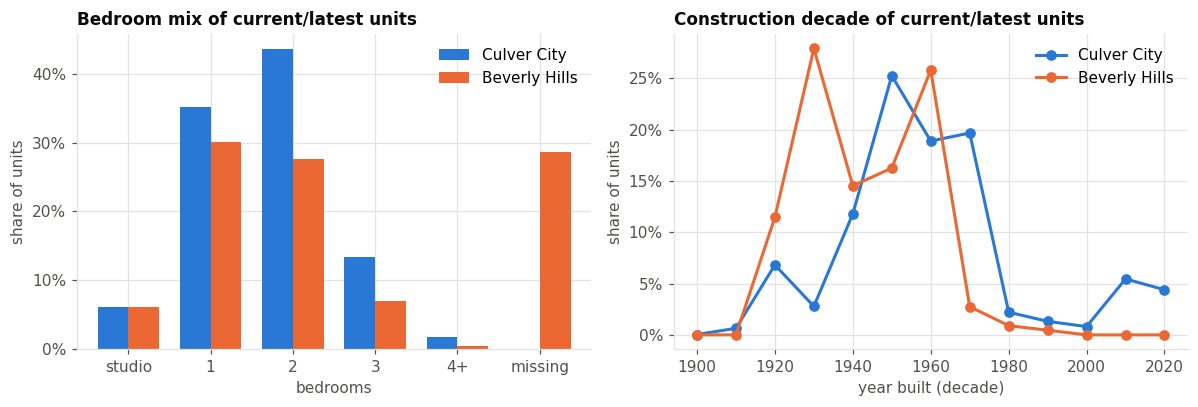

In [12]:
units = cc_units  # preserve the name used by later Culver City-only sections
city_units = {"Culver City": units, "Beverly Hills": bh}
bedroom_order = ["studio", "1", "2", "3", "4+", "missing"]

bedroom_share = {}
decade_share = {}
for city, d in city_units.items():
    br = d["bedrooms"].astype("float").clip(upper=4).map({0: "studio", 1: "1", 2: "2", 3: "3", 4: "4+"}).fillna("missing")
    bedroom_share[city] = br.value_counts(normalize=True).reindex(bedroom_order, fill_value=0)
    decade = (d["year_built"].astype("float") // 10 * 10).astype("Int64")
    decade_share[city] = decade.value_counts(normalize=True).sort_index()

bedroom_share = pd.DataFrame(bedroom_share)
decade_share = pd.DataFrame(decade_share).fillna(0).sort_index()
display((bedroom_share * 100).round(1).rename_axis("bedrooms"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
bedroom_share.plot.bar(ax=ax1, color=SERIES[:2], width=0.75)
ax1.set_title("Bedroom mix of current/latest units")
ax1.set_xlabel("bedrooms")
ax1.set_ylabel("share of units")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.tick_params(axis="x", rotation=0)

decade_share.plot(ax=ax2, color=SERIES[:2], marker="o", lw=2)
ax2.set_title("Construction decade of current/latest units")
ax2.set_xlabel("year built (decade)")
ax2.set_ylabel("share of units")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.tight_layout()

print("Culver City status:", units["unit_status"].value_counts().to_dict())
print("Beverly Hills chapter:", bh["rent_control_chapter"].fillna("(blank)").value_counts().to_dict())

**Ownership concentration.** Owner names are free text and not standardized in either registry. A trust, its trustee and the LLC can all show up as different owners, so read owner counts as upper bounds and cross-city differences cautiously.

In [13]:
owner_bins = [0, 1, 4, 9, 49, np.inf]
owner_labels = ["1", "2–4", "5–9", "10–49", "50+"]


def ownership_concentration(d):
    counts = d.dropna(subset=["owner"]).groupby("owner")["unit_id"].nunique()
    bands = pd.cut(counts, owner_bins, labels=owner_labels)
    out = pd.DataFrame({
        "owners": counts.groupby(bands, observed=False).size(),
        "units": counts.groupby(bands, observed=False).sum(),
    })
    out["share_of_units"] = out["units"] / out["units"].sum()
    return counts, out


units_per_owner, cc_concentration = ownership_concentration(units)
bh_units_per_owner, bh_concentration = ownership_concentration(bh)
concentration = pd.concat({"Culver City": cc_concentration, "Beverly Hills": bh_concentration}, axis=1)
display(concentration.round(2).rename_axis("units per owner"))

cc_top = units_per_owner.sort_values(ascending=False).head(10)
bh_top = bh_units_per_owner.sort_values(ascending=False).head(10)
top_owners = pd.DataFrame({
    "Culver City owner": cc_top.index, "Culver City units": cc_top.values,
    "Beverly Hills owner": bh_top.index, "Beverly Hills units": bh_top.values,
}, index=pd.RangeIndex(1, 11, name="rank"))
top_owners

Culver City                      Beverly Hills                     
                     owners units share_of_units        owners units share_of_units
units per owner                                                                    
1                      1625  1625           0.19            27    27           0.00
2–4                     774  2122           0.25           336   966           0.13
5–9                     181  1163           0.14           288  1933           0.26
10–49                   102  1771           0.21           172  3282           0.44
50+                      14  1733           0.21            10  1226           0.16

,Culver City owner,Culver City units,Beverly Hills owner,Beverly Hills units
rank,,,,
1,FOX HILLS CANTERBURY CO LP,576,ROCHELLE STERLING,490
2,IVY STATION RESIDENTIAL LLC,200,RITA SPEKTOR,136
3,MEADOWS SOUTH II LP,117,MICHAEL SELTZER,129
4,6060 BUCKINGHAM PARKWAY LLC,104,WILLIAM SHAW,83
5,HADERWAY PROPERTIES LLC,104,BABAK RASHIDIDOUST,81
6,SCOTT COLLIER,97,JOSH RAMSAY,79
7,BRUCE SCHWARTZ,95,MARIE GREEN,76
8,PARKWAY PLAZA 94,92,LEONARD ROSENBLATT,51
9,HFH WFA LLC,60,ALEX NEHORAI,51


**Sanity check: declared vs. observed units.** Culver City reports unit counts by address; Beverly Hills reports `total_units` by APN. Both can disagree with the distinct unit rows actually present. Culver City's largest gaps include large complexes with a declared zero, while Beverly Hills can omit unit identifiers or list address-level placeholders. Analysis therefore uses distinct observed unit rows, not the declared totals.

In [14]:
latest_prop = everything.sort_values("block_last_date").groupby("address").tail(1).set_index("address")
cc_check = pd.DataFrame({
    "declared": latest_prop["n_units"].astype("float"),
    "observed": panel.groupby("address")["unit_id"].nunique(),
}).fillna(0)
bh_check = bh.groupby("apn").agg(
    declared=("total_units", "max"),
    observed=("unit_id", "nunique"),
).fillna(0)

def unit_count_check(d):
    diff = d["observed"] - d["declared"]
    return pd.Series({
        "properties": len(d),
        "declared units": d["declared"].sum(),
        "observed units": d["observed"].sum(),
        "exact matches": diff.eq(0).sum(),
        "observed > declared": diff.gt(0).sum(),
        "observed < declared": diff.lt(0).sum(),
    })

display(pd.concat({"Culver City": unit_count_check(cc_check), "Beverly Hills": unit_count_check(bh_check)}, axis=1).astype(int))
cc_gaps = cc_check.assign(diff=lambda d: d.observed - d.declared).nlargest(6, "diff")
bh_gaps = bh_check.assign(diff=lambda d: d.observed - d.declared).reindex(
    (bh_check.observed - bh_check.declared).abs().nlargest(6).index
)
display(pd.concat({"Culver City positive gaps": cc_gaps, "Beverly Hills absolute gaps": bh_gaps}))

,Culver City,Beverly Hills
properties,3984,1091
declared units,6858,7751
observed units,8414,7458
exact matches,3582,804
observed > declared,329,3
observed < declared,73,284


declared  observed   diff
Culver City positive gaps   6100 GREEN VALLEY CIR                 0.0     576.0  576.0
                            6500 GREEN VALLEY CIR # LEASING       0.0     117.0  117.0
                            6220 BRISTOL PKWY                    92.0     152.0   60.0
                            6125 CANTERBURY DR                    0.0      40.0   40.0
                            9520 LUCERNE AVE                      0.0      32.0   32.0
                            9600 LUCERNE AVE                      0.0      30.0   30.0
Beverly Hills absolute gaps 4328017014                            8.0      12.0    4.0
                            4342034002                           36.0      33.0   -3.0
                            4343002026                           44.0      41.0   -3.0
                            4328018015                           16.0      14.0   -2.0
                            4330001006                           23.0      21.0   -2.0
                            4331001031                           29.0      27.0   -2.0

## 5. Rents: Culver City history and a current cross-city comparison

Only `rent_clean` is used here. The Culver City trend takes medians over all observations dated in a year, so 2019 is mostly base rents as of 6/11/2019. The cross-city panel compares each Culver City unit's latest record with the current Beverly Hills snapshot. It is descriptive: bedroom data are missing for many Beverly Hills rows, and neither registry is adjusted for differences in housing stock.

count     10%     50%     90%
city          br                                    
Beverly Hills Studio   400.0  1120.0  1803.0  2229.0
              1 bd    2076.0  1627.0  2356.0  3322.0
              2 bd    1819.0  2379.0  3300.0  4760.0
              3+ bd    423.0  3257.0  4600.0  6455.0
Culver City   Studio   457.0  1028.0  1648.0  2300.0
              1 bd    2787.0  1402.0  2229.0  3270.0
              2 bd    3481.0  1796.0  2795.0  4350.0
              3+ bd   1183.0  2249.0  4050.0  6397.0

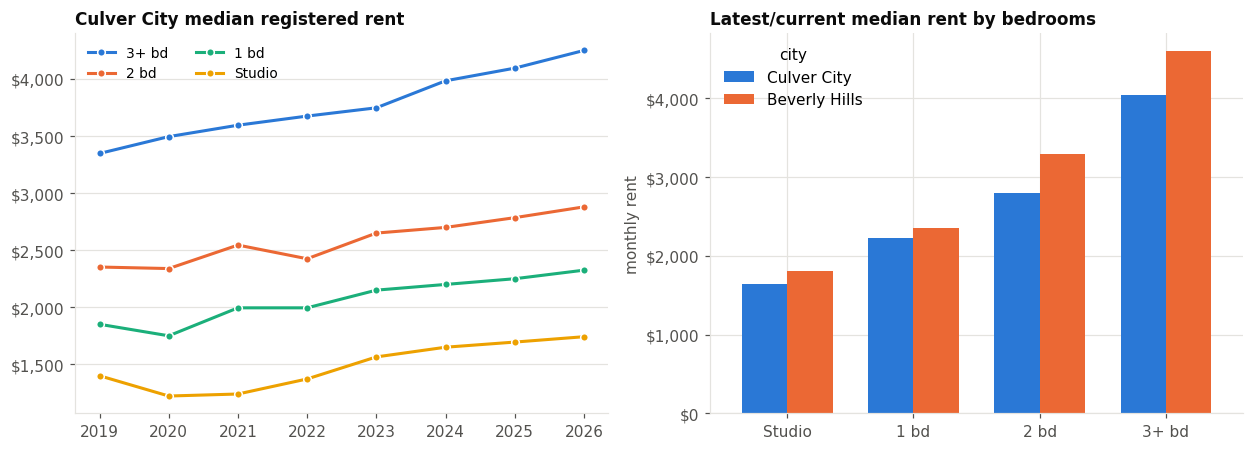

In [15]:
panel_br = panel.assign(br=panel["bedrooms"].astype("float").clip(upper=3))
labels = {0: "Studio", 1: "1 bd", 2: "2 bd", 3: "3+ bd"}

current_rents = pd.concat([
    units.assign(city="Culver City", br=units["bedrooms"].astype("float").clip(upper=3))[["city", "br", "rent_clean"]],
    bh.assign(city="Beverly Hills", br=bh["bedrooms"].astype("float").clip(upper=3))[["city", "br", "rent_clean"]],
], ignore_index=True)
current_summary = (current_rents.groupby(["city", "br"])["rent_clean"]
                   .describe(percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%"]].round(0))
display(current_summary.rename(index=labels, level="br"))

median_by_br = panel_br.pivot_table(index="year", columns="br", values="rent_clean", aggfunc="median")
current_median = current_rents.pivot_table(index="br", columns="city", values="rent_clean", aggfunc="median").rename(index=labels)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
for color, br in zip(SERIES, [3, 2, 1, 0]):
    s = median_by_br[br]
    ax1.plot(s.index, s.values, color=color, lw=2, marker="o", ms=5,
             markeredgecolor="white", markeredgewidth=1, label=labels[br])
ax1.set_title("Culver City median registered rent")
ax1.set_xticks(median_by_br.index)
ax1.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax1.legend(loc="upper left", ncols=2, fontsize=9)

current_median[["Culver City", "Beverly Hills"]].plot.bar(ax=ax2, color=SERIES[:2], width=0.72)
ax2.set_title("Latest/current median rent by bedrooms")
ax2.set_xlabel("")
ax2.set_ylabel("monthly rent")
ax2.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax2.tick_params(axis="x", rotation=0)
fig.tight_layout()

### First cross-city findings

- **Coverage is similar at the unit-row level but not at the property level.** The current/latest cross-section has 8,414 Culver City units and 7,458 Beverly Hills unit rows. Beverly Hills spans 1,091 APNs; Culver City spans 2,543 normalized buildings. These property definitions are useful within each registry but are not perfectly equivalent.
- **Beverly Hills is older.** Its unit rows concentrate in the 1920s–1960s and have almost no post-1990 construction, while Culver City's latest-unit sample has meaningful 2000s–2020s stock.
- **Bedroom comparisons are selective in Beverly Hills.** Bedrooms are missing for 28.6% of Beverly Hills rows versus essentially none in Culver City. Among rows with bedrooms and usable rent, Beverly Hills medians are about 9% higher for studios, 6% for one-bedrooms, 18% for two-bedrooms and 14% for units with three or more bedrooms.
- **Recorded ownership is more concentrated in Beverly Hills.** Owners associated with 10 or more unit rows account for about 60% of Beverly Hills rows versus about 42% in Culver City. This is descriptive because owner names are not entity-resolved.
- **The Beverly Hills snapshot has material missingness.** It has 1,106 rows without monthly rent and 2,132 without bedroom counts. One rent exceeds the $20,000 cleaning ceiling and 44 rents are zero. These rows remain in `bh`; `rent_clean` excludes them from rent summaries.
- **Declared totals are not a row-count control.** Beverly Hills exactly matches declared and observed units for 804 of 1,091 APNs; observed rows are below the declared total for 284 APNs. That pattern is consistent with incomplete unit detail or non-rental units within a property, so the notebook does not inflate missing units.

## 6. Same-unit rent histories & year-over-year changes (Culver City only)

Beverly Hills has only a current snapshot, so sections 6–13 use the Culver City panel only.

**Construction.**
- **Unit-year panel.** Keep one rent per unit per year: the last usable `rent_clean` recorded that year. This resolves 2022, where many units have both a 1/1/2022 and a mid-year record.
- **Pairs.** Pair each unit-year with the same unit's previous observed year. Consecutive-year pairs give the year-over-year (YoY) change.
- **Gapped pairs.** Coverage is thin in 2020–21, so many units skip years. Those pairs are counted here but left out of the YoY statistics.
- **Year labels.** A pair is labelled by its later year, so "2020" means 2019 → 2020.

In [16]:
unit_year = (
    panel.dropna(subset=["rent_clean"])
    .sort_values("rent_date")
    .groupby(["unit_id", "year"]).tail(1)
    .sort_values(["unit_id", "year"])
    .reset_index(drop=True)
)
by_unit = unit_year.groupby("unit_id")
unit_year["prev_year"] = by_unit["year"].shift()
unit_year["prev_date"] = by_unit["rent_date"].shift()
unit_year["prev_rent"] = by_unit["rent_clean"].shift()
unit_year["gap"] = unit_year["year"] - unit_year["prev_year"]
unit_year["chg"] = unit_year["rent_clean"] / unit_year["prev_rent"] - 1

pairs = unit_year.dropna(subset=["prev_rent"])
consecutive = pairs[pairs["gap"] == 1]
years_obs = by_unit.size()

display(years_obs.value_counts().sort_index().rename("units").rename_axis("years with a usable rent").to_frame().T)
pd.Series({
    "units with a usable rent": len(years_obs),
    "units with ≥2 years (a rent history)": (years_obs >= 2).sum(),
    "units observed in all 8 years": (years_obs == 8).sum(),
    "addresses with ≥2 years": (unit_year.groupby("address")["year"].nunique() >= 2).sum(),
    "repeat-rent pairs (unit vs. its previous observed year)": len(pairs),
    "  consecutive-year pairs": len(consecutive),
    "  pairs with a 2–7 year gap": (pairs["gap"] > 1).sum(),
    "units with ≥1 consecutive pair": consecutive["unit_id"].nunique(),
    "addresses with ≥1 consecutive pair": consecutive["address"].nunique(),
    "owners with ≥1 consecutive pair": consecutive["owner"].nunique(),
}, name="count").to_frame()

years with a usable rent,1,2,3,4,5,6,7,8
units,359,1169,613,645,1193,1719,1793,717


,count
units with a usable rent,8208
units with ≥2 years (a rent history),7849
units observed in all 8 years,717
addresses with ≥2 years,2692
repeat-rent pairs (unit vs. its previous observed year),33474
consecutive-year pairs,27031
pairs with a 2–7 year gap,6443
units with ≥1 consecutive pair,7174
addresses with ≥1 consecutive pair,2542
owners with ≥1 consecutive pair,2420


### Tenancy and outliers

The registry has no tenant ID. It only records the **start of the unit's current lease** as of that registration. That is enough to classify each pair:
- **same tenancy**: the current lease started on or before the earlier rent date, so both rents belong to one tenant.
- **new tenancy**: the current lease started between the two rent dates, so there was a turnover in between.
- **earlier tenancy**: the current lease started after the pair. The pair belongs to an earlier tenancy, which could itself contain an unobserved turnover.
- **unknown**: no lease start is recorded.

Changes above ±50% are almost all data errors. Examples: a $100 placeholder base rent in 2019 followed by $4,000 in 2020, or `13,490` entered for 1,349.00. They are shown below and then dropped.

In [17]:
yoy = consecutive.copy()
lease = yoy["lease_start"]
yoy["tenancy"] = np.select(
    [lease.isna(), lease <= yoy["prev_date"], lease <= yoy["rent_date"]],
    ["unknown", "same tenancy", "new tenancy"],
    default="earlier tenancy",
)
extreme = yoy["chg"].abs() > 0.5
print(f"extreme changes (|change| > 50%): {extreme.sum()} of {len(yoy):,} pairs ({extreme.mean():.1%}), dropped")
display(
    yoy.loc[extreme, ["unit_id", "prev_date", "prev_rent", "rent_date", "rent_clean", "chg"]]
    .sort_values("chg").iloc[[0, 1, 2, -3, -2, -1]]
)
yoy = yoy[~extreme]
yoy["tenancy"].value_counts().rename("pairs").to_frame().T

extreme changes (|change| > 50%): 227 of 27,031 pairs (0.8%), dropped


,unit_id,prev_date,prev_rent,rent_date,rent_clean,chg
33054,6100 GREEN VALLEY CIR | 6180-323,2023-07-27,2624.0,2024-07-30,230.00,-0.912348
594,10722 FLAXTON ST | 10722,2019-06-11,1000.0,2020-06-15,100.00,-0.900000
4823,11701 W WASHINGTON BLVD | B,2025-07-03,13490.0,2026-07-28,1351.76,-0.899795
26213,4838 HOLLOW CORNER RD UNIT 415 | 415,2019-06-11,100.0,2020-04-20,2300.00,22.000000
18977,4069 COOLIDGE AVE | 4069,2019-06-11,100.0,2020-05-28,3000.00,29.000000
27535,5228 BERRYMAN AVE | 1,2019-06-11,100.0,2020-05-04,4000.00,39.000000


tenancy,same tenancy,earlier tenancy,new tenancy,unknown
pairs,18232,4727,2424,1421


### Distribution of year-over-year changes

26,804 consecutive-year pairs | no change 47% | increase 48% | decrease 6%


most common changes (%),3.2,3.0,5.0,3.3,3.5,4.0,2.0,2.9,3.1,4.2
pairs,1630,1614,1116,554,461,352,242,234,166,158


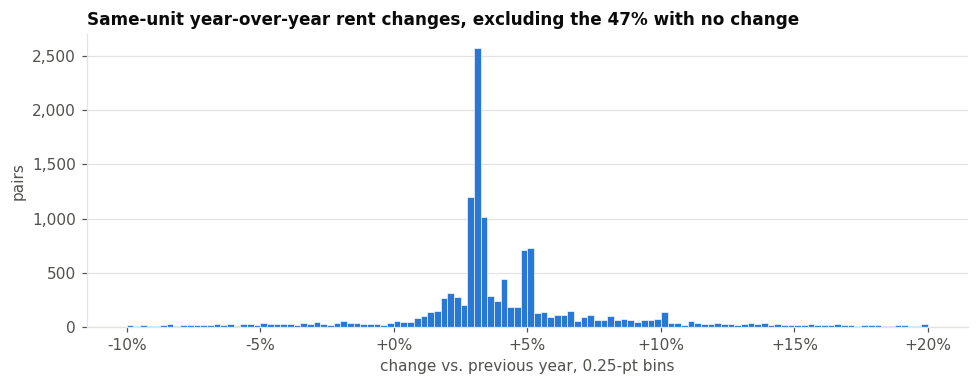

In [18]:
chg = yoy["chg"]
print(f"{len(yoy):,} consecutive-year pairs | no change {chg.eq(0).mean():.0%} | "
      f"increase {chg.gt(0).mean():.0%} | decrease {chg.lt(0).mean():.0%}")
common = (chg[chg != 0] * 100).round(1).value_counts().head(10)
display(common.rename("pairs").rename_axis("most common changes (%)").to_frame().T)

fig, ax = plt.subplots(figsize=(9, 3.6))
nonzero = chg[(chg != 0) & chg.between(-0.10, 0.20)] * 100
ax.hist(nonzero, bins=np.arange(-10, 20.25, 0.25), color=SERIES[0], edgecolor="white", linewidth=0.4)
ax.set_title(f"Same-unit year-over-year rent changes, excluding the {chg.eq(0).mean():.0%} with no change")
ax.set_xlabel("change vs. previous year, 0.25-pt bins")
ax.set_ylabel("pairs")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
fig.tight_layout()

### Year by year

In most years, about half of all pairs show no change. So the median across all pairs is roughly 0 and says little. The table below splits each year into how many rents moved (`increase` / `no_change` / `decrease`) and by how much when they went up (`median_increase`). `mean_change` combines the two.

In [19]:
def summarize(x):
    return pd.Series({
        "pairs": len(x),
        "no_change": x.eq(0).mean(),
        "increase": x.gt(0).mean(),
        "decrease": x.lt(0).mean(),
        "median_increase": x[x > 0].median(),  # among pairs whose rent went up
        "mean_change": x.mean(),
        "p90": x.quantile(0.9),
        "over_10pct": x.gt(0.10).mean(),
    })


def pct_table(t):
    t = t.rename(index=lambda y: f"{y - 1}→{y}" if isinstance(y, (int, np.integer)) else y)
    return t.style.format({c: ("{:,.0f}" if c.startswith("pairs") else "{:.1%}") for c in t.columns})


yoy_by_year = yoy.groupby("year")["chg"].apply(summarize).unstack()
pct_table(pd.concat([yoy_by_year, summarize(yoy["chg"]).rename("all years").to_frame().T]))

,pairs,no_change,increase,decrease,median_increase,mean_change,p90,over_10pct
2019→2020,"3,616",56.4%,39.9%,3.7%,3.0%,1.6%,4.3%,3.6%
2020→2021,"1,154",72.6%,18.0%,9.4%,3.0%,0.4%,3.0%,3.6%
2021→2022,"1,494",55.2%,39.4%,5.5%,4.2%,1.9%,7.3%,7.2%
2022→2023,"4,438",44.1%,51.7%,4.2%,5.0%,4.2%,12.0%,12.3%
2023→2024,"5,089",40.2%,53.4%,6.3%,4.0%,2.9%,8.4%,8.3%
2024→2025,"5,527",44.8%,48.7%,6.5%,3.3%,2.2%,6.6%,5.8%
2025→2026,"5,486",42.1%,51.2%,6.7%,3.2%,2.0%,6.0%,4.5%
all years,"26,804",46.6%,47.6%,5.8%,3.5%,2.5%,7.1%,6.8%


In [20]:
by_tenancy = yoy.pivot_table(index="year", columns="tenancy", values="chg", aggfunc="mean")
by_tenancy = by_tenancy[["same tenancy", "new tenancy", "earlier tenancy", "unknown"]]
print("mean year-over-year change, by tenancy")
display(pct_table(by_tenancy))

by_rc = yoy.groupby(["year", "rent_control"])["chg"].apply(summarize).unstack()[["pairs", "increase", "median_increase", "mean_change"]]
by_rc = by_rc.unstack("rent_control")
by_rc.columns = [f"{m} ({'RC' if rc else 'non-RC'})" for m, rc in by_rc.columns]
print("by rent-control status")
pct_table(by_rc)

mean year-over-year change, by tenancy


tenancy,same tenancy,new tenancy,earlier tenancy,unknown
year,,,,
2019→2020,1.2%,2.2%,2.0%,1.0%
2020→2021,0.2%,1.5%,0.4%,0.2%
2021→2022,0.9%,4.4%,2.7%,1.9%
2022→2023,3.0%,13.8%,4.5%,2.5%
2023→2024,2.5%,4.9%,3.6%,2.7%
2024→2025,2.1%,3.0%,2.3%,2.2%
2025→2026,2.0%,2.9%,6.7%,1.3%


by rent-control status


,pairs (non-RC),pairs (RC),increase (non-RC),increase (RC),median_increase (non-RC),median_increase (RC),mean_change (non-RC),mean_change (RC)
year,,,,,,,,
2019→2020,"2,511","1,105",39.3%,41.4%,3.0%,3.0%,1.5%,1.7%
2020→2021,731,423,13.8%,25.3%,3.3%,2.2%,0.0%,1.0%
2021→2022,897,597,34.1%,47.2%,4.9%,3.5%,2.1%,1.6%
2022→2023,"2,995","1,443",50.3%,54.7%,5.0%,5.0%,4.4%,3.8%
2023→2024,"3,546","1,543",52.5%,55.6%,4.0%,4.2%,2.6%,3.5%
2024→2025,"3,753","1,774",44.9%,56.8%,3.3%,3.2%,1.9%,2.8%
2025→2026,"3,621","1,865",51.7%,50.4%,3.2%,3.2%,1.9%,2.4%


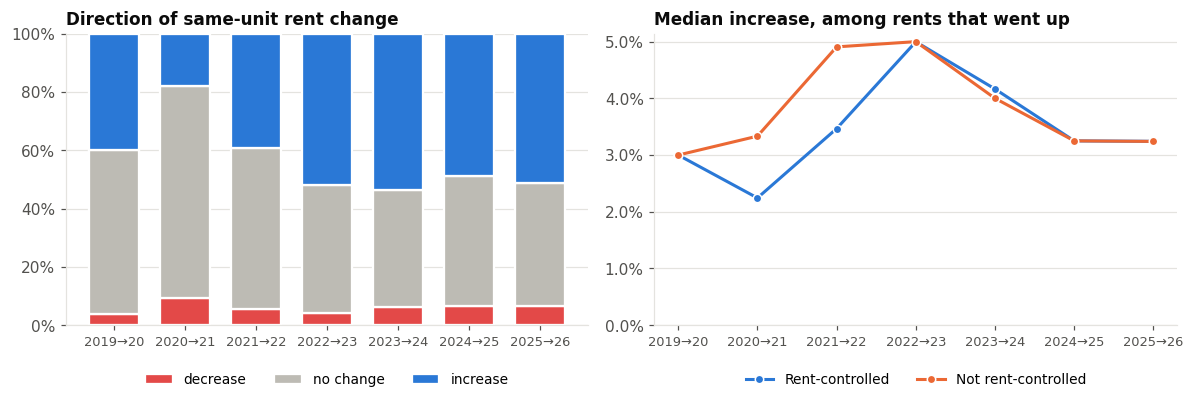

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

# left: what share of rents went down / stayed / went up
shares = yoy_by_year[["decrease", "no_change", "increase"]] * 100
colors = {"decrease": "#e34948", "no_change": "#bdbbb4", "increase": SERIES[0]}
bottom = np.zeros(len(shares))
for col in shares.columns:
    ax1.bar(shares.index, shares[col], bottom=bottom, width=0.7, color=colors[col],
            edgecolor="white", linewidth=1.5, label=col.replace("_", " "))
    bottom += shares[col].values
ax1.set_title("Direction of same-unit rent change")
ax1.set_xticks(shares.index, [f"{y - 1}→{str(y)[2:]}" for y in shares.index], fontsize=8.5)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax1.set_ylim(0, 100)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3, fontsize=9)

# right: size of the increase, when there was one
med_up = yoy[yoy["chg"] > 0].pivot_table(index="year", columns="rent_control", values="chg", aggfunc="median") * 100
for color, (rc, label) in zip(SERIES, [(True, "Rent-controlled"), (False, "Not rent-controlled")]):
    s = med_up[rc]
    ax2.plot(s.index, s.values, color=color, lw=2, marker="o", ms=5.5,
             markeredgecolor="white", markeredgewidth=1, label=label)
ax2.set_title("Median increase, among rents that went up")
ax2.set_xticks(med_up.index, [f"{y - 1}→{str(y)[2:]}" for y in med_up.index], fontsize=8.5)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}%")
ax2.set_ylim(0, None)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2, fontsize=9)

fig.tight_layout()

### Cumulative growth over the sample

Chain the mean same-unit log change each year into an index with 2019 = 100. It answers: *how much did rent grow for a unit that stayed in the registry?* It is shown for all pairs, for continuing tenants only, and next to the median-rent index from section 3. The median-rent index mixes together whichever units happened to report in each year.

2020–21 and 2021–22 rest on only ~1.2k and ~1.5k pairs, so the index is least reliable in those years.

,2019,2020,2021,2022,2023,2024,2025,2026
"Same unit, all pairs",100.0,101.4,101.6,103.3,107.3,110.1,112.3,114.4
"Same unit, same tenancy",100.0,101.1,101.2,101.9,104.8,107.2,109.3,111.3
Median rent (cross-section),100.0,97.7,111.6,106.7,116.0,116.3,120.7,124.9


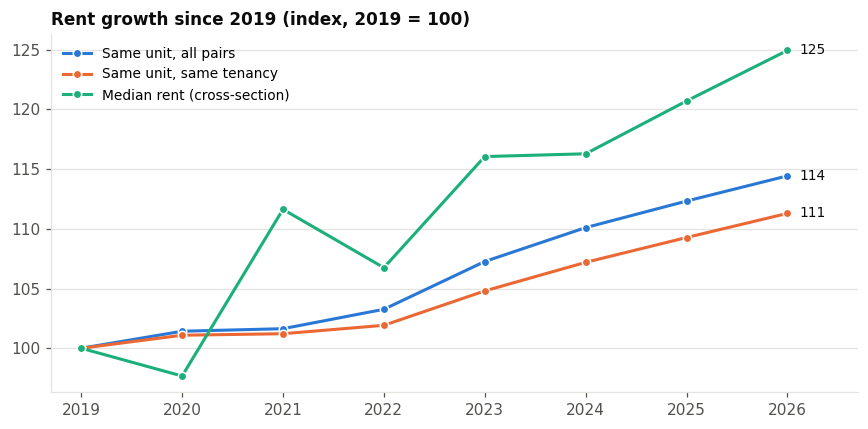

In [22]:
def chained_index(d):
    mean_log = np.log1p(d["chg"]).groupby(d["year"]).mean()
    idx = 100 * np.exp(mean_log.cumsum())
    return pd.concat([pd.Series({2019: 100.0}), idx])


growth = pd.DataFrame({
    "Same unit, all pairs": chained_index(yoy),
    "Same unit, same tenancy": chained_index(yoy[yoy["tenancy"] == "same tenancy"]),
    "Median rent (cross-section)": 100 * per_year["median_rent"] / per_year["median_rent"].loc[2019],
})
display(growth.round(1).T)

fig, ax = plt.subplots(figsize=(8, 4))
for color, col in zip(SERIES, growth.columns):
    s = growth[col]
    ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=5.5,
            markeredgecolor="white", markeredgewidth=1, label=col)
    ax.annotate(f"{s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_title("Rent growth since 2019 (index, 2019 = 100)")
ax.set_xticks(growth.index)
ax.set_xlim(growth.index.min() - 0.3, growth.index.max() + 0.7)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()

## 7. Long-term-tenant vs high-turnover buildings

The goal is two samples we can be confident about: **buildings whose tenants stayed for the whole sample** and **buildings with high tenant turnover**.

**Evidence.** There is no tenant ID. The only evidence is a unit's lease start (the move-in date of its current tenant) and its status (Rented / Vacant / Owner Occupied). Both are recorded once per registration. Each unit is observed in up to four registration snapshots: the two releases, each of which can hold an old and a current registration for the same property. A lease start that differs between snapshots means a new tenant.

**Rents are deliberately not used to define the samples.** The point of the split is to compare rent behaviour between the groups, so selecting on rent changes would build the result in. Rent changes are used only afterwards, to validate the split.

**Unit rules** (move-ins dated after the 6/11/2019 base-rent date count as *in sample*):
| class | rule |
|---|---|
| owner-occupied | Owner Occupied in any snapshot. Excluded. |
| turnover | at least one move-in during the sample, **or** Vacant in any snapshot (the previous tenant left) |
| long-term | exactly one move-in date across all snapshots, dated before the sample; every snapshot has a usable lease start; still in place at a registration from 2024 or later |
| unknown | everything else: no usable lease start, snapshots that disagree, or not observed after 2023 |

A lease start is **unusable** if it is before 1960, or if it matches the building's certificate-of-occupancy date (copied from the building record, e.g. `1970-01-01` on a building built in 1970).

**New construction** (built 2018 or later) is excluded. Every tenant there moved in during the sample by construction, so their move-ins are initial lease-up, not turnover.

In [23]:
SAMPLE_START = pd.Timestamp("2019-06-11")    # registry base-rent date
STAYED_THROUGH = pd.Timestamp("2024-01-01")  # long-term tenants must still be in place at a registration on/after this

# one row per unit per registration snapshot, from both releases (old and current blocks)
snaps = pd.concat([parsed["26-962"], parsed["25-384"]], ignore_index=True)
snaps["unit_id"] = snaps["address"] + " | " + snaps["unit_number"].fillna("")
snaps = (
    snaps[snaps["unit_id"].isin(set(panel["unit_id"]))]
    .drop_duplicates(["unit_id", "block"])
    [["unit_id", "source", "block", "lease_start", "unit_status", "occupancy_date", "cert_occupancy_date", "year_built"]]
)
copied = snaps["lease_start"].eq(snaps["cert_occupancy_date"]) | (
    snaps["lease_start"].eq(snaps["occupancy_date"]) & snaps["lease_start"].dt.year.eq(snaps["year_built"])
)
snaps["lease_ok"] = snaps["lease_start"].ge("1960-01-01") & ~copied
print(f"{len(snaps):,} snapshots of {snaps['unit_id'].nunique():,} units | "
      f"lease start missing {snaps['lease_start'].isna().sum():,}, before 1960 {snaps['lease_start'].lt('1960-01-01').sum()}, "
      f"copied from building record {copied.sum()}")

17,504 snapshots of 8,414 units | lease start missing 2,024, before 1960 39, copied from building record 313


In [24]:
by_snap = snaps.assign(
    vacant=snaps["unit_status"].eq("Vacant"),
    owner_occ=snaps["unit_status"].eq("Owner Occupied"),
).groupby("unit_id")
moves = snaps[snaps["lease_ok"]].drop_duplicates(["unit_id", "lease_start"])
moves = moves.assign(in_sample=moves["lease_start"] > SAMPLE_START).groupby("unit_id")

tenure = pd.DataFrame({
    "snapshots": by_snap.size(),
    "all_leases_ok": by_snap["lease_ok"].all(),
    "ever_vacant": by_snap["vacant"].any(),
    "ever_owner_occupied": by_snap["owner_occ"].any(),
    "move_ins_known": moves.size(),
    "move_ins_in_sample": moves["in_sample"].sum(),
    "last_move_in": moves["lease_start"].max(),
})
tenure[["move_ins_known", "move_ins_in_sample"]] = tenure[["move_ins_known", "move_ins_in_sample"]].fillna(0).astype(int)
tenure = tenure.join(panel.groupby("unit_id").agg(
    building=("building", "last"), obs_end=("rent_date", "max"), year_built=("year_built", "max")))
tenure["new_construction"] = tenure["year_built"].astype("float") >= 2018
tenure["tenure_years"] = (tenure["obs_end"] - tenure["last_move_in"]).dt.days / 365.25

tenure["tenure_class"] = np.select(
    [
        tenure["ever_owner_occupied"],
        tenure["move_ins_in_sample"].gt(0) | tenure["ever_vacant"],
        tenure["move_ins_known"].eq(1) & tenure["all_leases_ok"] & tenure["obs_end"].ge(STAYED_THROUGH),
    ],
    ["owner-occupied", "turnover", "long-term"],
    default="unknown",
)

display(pd.crosstab(tenure["tenure_class"], tenure["new_construction"].map({False: "existing", True: "built 2018+"}), margins=True))
unknown = tenure[tenure["tenure_class"].eq("unknown")]
print("why unknown:", {k: int(v) for k, v in {
    "no usable lease start": unknown["move_ins_known"].eq(0).sum(),
    "a snapshot lacks a usable lease start": (unknown["move_ins_known"].ge(1) & ~unknown["all_leases_ok"]).sum(),
    "snapshots disagree (2+ pre-sample move-ins)": (unknown["move_ins_known"].gt(1) & unknown["all_leases_ok"]).sum(),
    "not observed after 2023": (unknown["move_ins_known"].eq(1) & unknown["all_leases_ok"]).sum(),
}.items()})
turn = tenure[tenure["tenure_class"].eq("turnover") & ~tenure["new_construction"]]
print("turnover evidence:", {k: int(v) for k, v in {
    "1 move-in": turn["move_ins_in_sample"].eq(1).sum(),
    "2+ move-ins": turn["move_ins_in_sample"].ge(2).sum(),
    "vacancy only": turn["move_ins_in_sample"].eq(0).sum(),
}.items()})
print("long-term tenants, years in place at last registration:",
      tenure.loc[tenure["tenure_class"].eq("long-term"), "tenure_years"].describe()[["min", "25%", "50%", "75%"]].round(1).to_dict())

new_construction,built 2018+,existing,All
tenure_class,,,
long-term,0,1849,1849
owner-occupied,5,126,131
turnover,540,4595,5135
unknown,19,1280,1299
All,564,7850,8414


why unknown: {'no usable lease start': 585, 'a snapshot lacks a usable lease start': 70, 'snapshots disagree (2+ pre-sample move-ins)': 53, 'not observed after 2023': 591}
turnover evidence: {'1 move-in': 3434, '2+ move-ins': 807, 'vacancy only': 354}
long-term tenants, years in place at last registration: {'min': 4.8, '25%': 8.6, '50%': 12.1, '75%': 19.0}


### Building rules

Units are grouped by `building` (address without any unit suffix), counting only rental units in existing buildings. A building is classified only when the tenure of **at least 75%** of its rental units is known:
- **long-term tenants**: at least 80% of known units have a long-term tenant.
- **high turnover**: at least 80% of known units turned over during the sample.
- **mixed**: anything in between.
- **unclassified**: tenure known for under 75% of units.

The thresholds are set at the top of the next cell, and each building's continuous `share_long_term` is kept, so the cut-offs can be tightened or relaxed.

In [25]:
MIN_COVERAGE = 0.75   # share of a building's rental units with known tenure
LONG_TERM_MIN = 0.80  # long-term-tenant building: at least this share of known units long-term
TURNOVER_MIN = 0.80   # high-turnover building: at least this share of known units turned over

rental = tenure[~tenure["new_construction"] & tenure["tenure_class"].ne("owner-occupied")]
buildings = pd.crosstab(rental["building"], rental["tenure_class"]).reindex(
    columns=["long-term", "turnover", "unknown"], fill_value=0)
buildings["rental_units"] = buildings.sum(axis=1)
buildings["move_ins_in_sample"] = rental.groupby("building")["move_ins_in_sample"].sum()
known = buildings["long-term"] + buildings["turnover"]
buildings["coverage"] = known / buildings["rental_units"]
buildings["share_long_term"] = buildings["long-term"] / known.replace(0, np.nan)
buildings["sample"] = np.select(
    [
        buildings["coverage"] < MIN_COVERAGE,
        buildings["share_long_term"] >= LONG_TERM_MIN,
        1 - buildings["share_long_term"] >= TURNOVER_MIN,
    ],
    ["unclassified", "long-term tenants", "high turnover"],
    default="mixed",
)
buildings["size"] = pd.cut(buildings["rental_units"], [0, 1, 4, 9, np.inf], labels=["1 unit", "2–4", "5–9", "10+"])

SAMPLES = ["long-term tenants", "high turnover", "mixed", "unclassified"]
tenure["sample"] = tenure["building"].map(buildings["sample"]).where(~tenure["new_construction"], "new construction")

counts = pd.concat({
    "buildings": pd.crosstab(buildings["sample"], buildings["size"], margins=True, margins_name="total"),
    "rental units": pd.crosstab(buildings["sample"], buildings["size"], values=buildings["rental_units"],
                                aggfunc="sum", margins=True, margins_name="total"),
}, axis=1).reindex(SAMPLES + ["total"])
counts

buildings                     rental units                        
size                 1 unit  2–4  5–9 10+ total       1 unit   2–4   5–9   10+ total
sample                                                                              
long-term tenants       275   77   19   1   372          275   207   115    12   609
high turnover           745  292   63  30  1130          745   766   378   831  2720
mixed                     0  262   76  36   374            0   814   495  1430  2739
unclassified            298  208   48  26   580          298   562   313   483  1656
total                  1318  839  206  93  2456         1318  2349  1301  2756  7724

In [26]:
# sensitivity: sample sizes (buildings / rental units) under looser or stricter cut-offs
rows_ = []
for cov in [0.5, 0.75, 1.0]:
    for share in [0.67, 0.8, 1.0]:
        ok = buildings["coverage"] >= cov
        lt = ok & (buildings["share_long_term"] >= share)
        ht = ok & (1 - buildings["share_long_term"] >= share)
        rows_.append({"min coverage": cov, "min share": share,
                      "long-term: buildings": lt.sum(), "long-term: units": buildings.loc[lt, "rental_units"].sum(),
                      "high turnover: buildings": ht.sum(), "high turnover: units": buildings.loc[ht, "rental_units"].sum()})
pd.DataFrame(rows_).set_index(["min coverage", "min share"])

long-term: buildings  long-term: units  high turnover: buildings  high turnover: units
min coverage min share                                                                                        
0.50         0.67                        428               863                      1284                  4249
             0.80                        396               667                      1218                  3136
             1.00                        386               595                      1178                  2489
0.75         0.67                        403               797                      1195                  3825
             0.80                        372               609                      1130                  2720
             1.00                        362               537                      1095                  2185
1.00         0.67                        400               784                      1154                  2603
             0.80                        369               596                      1100                  2297
             1.00                        359               524                      1071                  2004

**What the samples look like.** They differ in composition, not just in turnover. The long-term sample is dominated by single-unit properties (houses and condos), while large buildings almost always end up *mixed*. Any comparison between the samples should control for building size, or be run separately for single-unit and multi-unit properties.

In [27]:
unit_attrs = units.set_index("unit_id")[["rent_control", "bedrooms"]].join(
    panel[panel["year"] == 2019].groupby("unit_id")["rent_clean"].median().rename("rent_2019"))
u = tenure[tenure["tenure_class"].ne("owner-occupied")].join(unit_attrs)

profile = pd.DataFrame({
    "buildings": buildings.groupby("sample").size(),
    "rental units": u.groupby("sample").size(),
    "single-unit buildings": buildings.groupby("sample")["size"].apply(lambda s: s.eq("1 unit").mean()),
    "median building size": buildings.groupby("sample")["rental_units"].median(),
    "median year built": u.groupby("sample")["year_built"].median(),
    "rent-controlled": u.groupby("sample")["rent_control"].mean(),
    "mean bedrooms": u.groupby("sample")["bedrooms"].mean(),
    "median 2019 rent": u.groupby("sample")["rent_2019"].median(),
    "move-ins in sample per unit": u.groupby("sample")["move_ins_in_sample"].mean(),
    "median tenure of current tenant (yrs)": u.groupby("sample")["tenure_years"].median(),
}).reindex(SAMPLES + ["new construction"])
rows = lambda *r: pd.IndexSlice[list(r), :]
(profile.T.style
    .format(precision=2, na_rep="–")
    .format("{:.0%}", na_rep="–", subset=rows("single-unit buildings", "rent-controlled"))
    .format("${:,.0f}", na_rep="–", subset=rows("median 2019 rent"))
    .format("{:,.0f}", na_rep="–", subset=rows("buildings", "rental units", "median building size"))
    .format("{:.0f}", na_rep="–", subset=rows("median year built")))

sample,long-term tenants,high turnover,mixed,unclassified,new construction
buildings,372,"1,130",374,580,–
rental units,609,"2,720","2,739","1,656",559
single-unit buildings,74%,66%,0%,51%,–
median building size,1,1,4,1,–
median year built,1952,1957,1967,1956,2021
rent-controlled,34%,26%,35%,18%,6%
mean bedrooms,2.00,1.80,1.55,1.70,1.60
median 2019 rent,"$1,975","$2,450","$2,055","$1,900","$3,902"
move-ins in sample per unit,0.01,1.11,0.62,0.22,1.35
median tenure of current tenant (yrs),12.21,2.51,6.30,5.31,1.34


### Validation: do the samples behave differently on rents?

Rents were not used to build the samples, so differences here are evidence that the split captures something real. The two samples are compared on same-unit year-over-year changes (from section 6), overall and split into single-unit vs. multi-unit properties.

In [28]:
yoy_s = yoy.join(tenure[["sample"]], on="unit_id").join(buildings["size"], on="building")
yoy_s["property"] = np.where(yoy_s["size"].eq("1 unit"), "single-unit", "multi-unit")
two = yoy_s[yoy_s["sample"].isin(SAMPLES[:2])]

by_property = two.groupby(["property", "sample"])["chg"].apply(summarize).unstack()
by_property.index = [f"{s} · {p}" for p, s in by_property.index]
pct_table(pd.concat([two.groupby("sample")["chg"].apply(summarize).unstack(), by_property]))

,pairs,no_change,increase,decrease,median_increase,mean_change,p90,over_10pct
high turnover,"8,828",45.8%,47.9%,6.3%,3.7%,2.6%,7.8%,7.7%
long-term tenants,"2,527",57.5%,39.9%,2.7%,3.5%,2.0%,5.3%,4.5%
high turnover · multi-unit,"6,661",42.5%,50.4%,7.1%,3.5%,2.6%,7.8%,7.9%
long-term tenants · multi-unit,"1,338",53.4%,43.8%,2.8%,3.3%,2.1%,5.0%,3.8%
high turnover · single-unit,"2,167",56.0%,40.1%,3.9%,4.3%,2.3%,7.5%,7.2%
long-term tenants · single-unit,"1,189",62.0%,35.5%,2.5%,4.2%,1.9%,6.7%,5.3%


,units,any_jump_over_10pct,any_decrease
tenure_class,,,
long-term,"1,795",17%,10%
turnover,"4,350",29%,26%


,2019,2020,2021,2022,2023,2024,2025,2026
long-term tenants,100.0,101.6,101.9,103.0,105.4,107.5,109.7,111.7
high turnover,100.0,101.6,101.5,104.6,109.0,112.0,114.3,116.2
all units,100.0,101.4,101.6,103.3,107.3,110.1,112.3,114.4


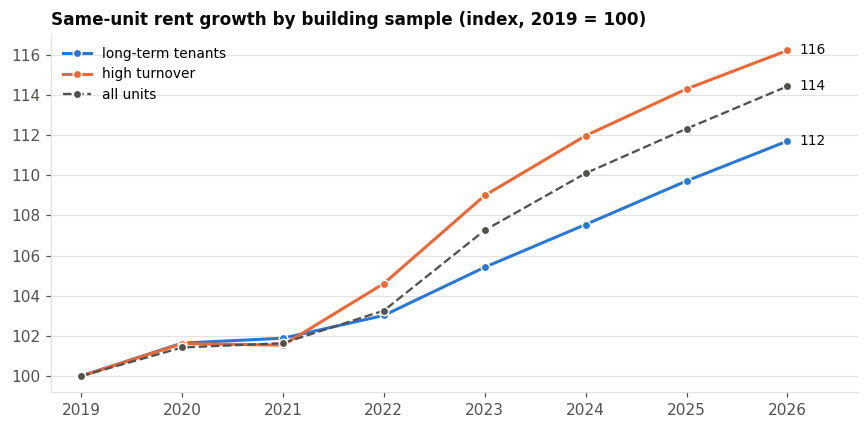

In [29]:
# unit-level check: how many units ever show a >10% jump or any decrease?
jumps = yoy.groupby("unit_id")["chg"].agg(max_chg="max", min_chg="min").join(tenure["tenure_class"])
jumps = jumps[jumps["tenure_class"].isin(["long-term", "turnover"])]
display(jumps.groupby("tenure_class").agg(
    units=("max_chg", "size"),
    any_jump_over_10pct=("max_chg", lambda s: s.gt(0.10).mean()),
    any_decrease=("min_chg", lambda s: s.lt(0).mean()),
).style.format({"units": "{:,.0f}", "any_jump_over_10pct": "{:.0%}", "any_decrease": "{:.0%}"}))

growth_s = pd.DataFrame({s: chained_index(two[two["sample"] == s]) for s in SAMPLES[:2]})
growth_s["all units"] = chained_index(yoy)
display(growth_s.round(1).T)

fig, ax = plt.subplots(figsize=(8, 4))
styles = {"long-term tenants": dict(color=SERIES[0]), "high turnover": dict(color=SERIES[1]),
          "all units": dict(color=INK_2, ls="--", lw=1.5)}
for col, style in styles.items():
    s = growth_s[col]
    ax.plot(s.index, s.values, **({"lw": 2, "marker": "o", "ms": 5.5, "markeredgecolor": "white",
                                   "markeredgewidth": 1} | style), label=col)
    ax.annotate(f"{s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_title("Same-unit rent growth by building sample (index, 2019 = 100)")
ax.set_xticks(growth_s.index)
ax.set_xlim(growth_s.index.min() - 0.3, growth_s.index.max() + 0.7)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()

## 8. Ownership changes: rents before and after a sale

**Finding owner changes.** Like lease start, the owner is recorded once per registration, and the export stamps the current owner's name on every rent row of that registration. A change of owner therefore only shows up as a different name between **two registrations of the same address**. That happens between an old and a current registration, or between the 2025 and 2026 releases.

**Most name differences are not sales.** They are:
- the same person or trust written differently (`STEPHEN SCHIFF` vs `SCHIFF STEPHEN D TRUST`);
- typos (`KELLY ESTATES` vs `KELLI ESTES`);
- a new contact person for the same LLC;
- transfers within a family.

A difference counts as an owner change only when the old and new names share **no surname or entity word**. Generic words (TRUST, LLC, INVESTMENTS, …) and common first names are ignored. As a fallback, two names that are ≥80% similar as strings count as the same owner. A test account is dropped. Name matching can't tell a sale from an owner moving the property into their own LLC (e.g. `JERRY SCHWARTZ` → `6100 BUCKINGHAM PARTNERS LLC`), so some of these "sales" are restructurings.

**Dating the sale.** New owners register under a new record. So the sale falls between the **old owner's last registration** and the **new owner's first registration after it**, and the new owner's first registration sets the sale year. A sale is *well dated* when that gap is at most ~15 months, i.e. one annual registration cycle.

In [30]:
import re
from difflib import SequenceMatcher

reg_rows = pd.concat([parsed["26-962"], parsed["25-384"]], ignore_index=True).dropna(subset=["rent_date"])
registrations = reg_rows.groupby("block").agg(
    source=("source", "first"), address=("address", "first"),
    owner_name=("owner_name", "first"), business_name=("business_name", "first"),
    last_rent=("rent_date", "max"),
)
registrations[["owner_name", "business_name"]] = registrations[["owner_name", "business_name"]].fillna("")

GENERIC = {
    "TRUST", "TRUSTS", "TR", "TRS", "TRUSTEE", "TRUSTEES", "COTRUSTEE", "CO", "LLC", "INC", "LP", "LTD", "CORP", "THE", "OF",
    "AND", "FAMILY", "LIVING", "REVOCABLE", "REV", "ETAL", "ET", "AL", "DATED", "DTD", "SURVIVORS", "SURVIVOR", "DECEDENTS",
    "BYPASS", "EXEMPT", "MARITAL", "SEPARATE", "PROPERTY", "PROPERTIES", "ESTATE", "ESTATES", "INVESTMENT", "INVESTMENTS",
    "ENTERPRISE", "ENTERPRISES", "ENT", "GROUP", "HOLDINGS", "HOLDING", "APARTMENTS", "APTS", "MANAGEMENT", "MANAGMENT",
    "MANAGING", "MEMBER", "REALTY", "REAL", "PARTNERS", "PARTNERSHIP", "ASSOCIATES", "COMPANY", "VENTURES", "DEVELOPMENT",
    "CAPITAL", "HOMES", "CULVER", "CITY", "AVENUE", "AVE", "BLVD", "STREET", "ST", "DR", "WAY", "RESIDENTIAL", "RENTALS",
    "RENTAL", "HOUSING", "FBO", "III", "JR", "SR", "MRS", "MR", "DBA", "FUND",
}
# first names: the first token of person names written "FIRST M LAST" (a middle initial between two words);
# assessor-style names ("RIORDAN JOHN E") put the initial last, so surnames are not picked up
FIRST_NAMES = set(reg_rows["owner_name"].dropna().str.extract(r"^([A-Z]{2,}) [A-Z]\.? [A-Z]{2,}$")[0].dropna())


def name_tokens(*names):
    toks = set()
    for n in names:
        toks |= set(re.findall(r"[A-Z]{2,}", n.upper()))
    return toks - GENERIC - FIRST_NAMES


def same_owner(a, b):
    ta, tb = name_tokens(*a), name_tokens(*b)
    if ta & tb:
        return True
    sa, sb = " ".join(sorted(ta)), " ".join(sorted(tb))
    return bool(sa and sb) and SequenceMatcher(None, sa, sb).ratio() >= 0.8


# compare consecutive registrations of each address, ordered by their last rent date
records = []
for address, g in registrations.sort_values("last_rent").groupby("address"):
    g = g.reset_index()
    for old, new in zip(g.iloc[:-1].itertuples(), g.iloc[1:].itertuples()):
        if (old.owner_name, old.business_name) == (new.owner_name, new.business_name):
            continue
        records.append({
            "address": address, "old_block": old.block, "new_block": new.block,
            "old_owner": f"{old.owner_name} | {old.business_name}", "new_owner": f"{new.owner_name} | {new.business_name}",
            "old_last_rent": old.last_rent,
            "same_owner": same_owner([old.owner_name, old.business_name], [new.owner_name, new.business_name]),
        })
transitions = pd.DataFrame(records)
transitions = transitions[~(transitions["old_owner"] + transitions["new_owner"]).str.contains(r"\bTEST\b")]

sales = transitions[~transitions["same_owner"]].drop_duplicates(["address", "old_owner", "new_owner"]).copy()
new_owner_dates = reg_rows.groupby("block")["rent_date"].apply(lambda s: np.sort(s.unique()))
sales["new_first_rent"] = [
    next((d for d in new_owner_dates[b] if d > last), pd.NaT)
    for b, last in zip(sales["new_block"], sales["old_last_rent"])
]
sales["new_first_rent"] = pd.to_datetime(sales["new_first_rent"])
sales["window_days"] = (sales["new_first_rent"] - sales["old_last_rent"]).dt.days
sales["sale_year"] = sales["new_first_rent"].dt.year.astype("Int64")
sales["well_dated"] = sales["window_days"].le(450)

print(f"name differences between consecutive registrations: {len(transitions)} "
      f"({transitions['same_owner'].sum()} name variants, {len(sales)} owner changes at {sales['address'].nunique()} addresses)")
print(f"owner changes with a new-owner registration after the old owner's last: {sales['new_first_rent'].notna().sum()}, "
      f"well dated (≤ ~15 months): {sales['well_dated'].sum()}")
print("gap between registrations (days):", sales["window_days"].describe()[["25%", "50%", "75%"]].round(0).to_dict())
display(pd.crosstab(sales["well_dated"].map({True: "well dated", False: "gap > 15 months"}), sales["sale_year"]))
sales[["address", "old_owner", "new_owner", "old_last_rent", "new_first_rent"]].sample(8, random_state=3)

name differences between consecutive registrations: 332 (221 name variants, 110 owner changes at 105 addresses)
owner changes with a new-owner registration after the old owner's last: 109, well dated (≤ ~15 months): 65
gap between registrations (days): {'25%': 276.0, '50%': 392.0, '75%': 713.0}


sale_year,2020,2021,2022,2023,2024,2025,2026
well_dated,,,,,,,
gap > 15 months,0,6,12,7,6,8,5
well dated,1,12,10,9,7,15,11


,address,old_owner,new_owner,old_last_rent,new_first_rent
321,8770 WASHINGTON BLVD,GDCV ACCESS CULVER CITY LLC | ACCESS...,"HADERWAY PROPERTIES LLC | BE VINE, LLC",2025-06-20,2026-07-17
299,6100 BUCKINGHAM PKWY,JERRY SCHWARTZ | JERRY SCHWARTZ,| 6100 BUCKINGHAM PARTNERS LLC,2021-10-12,2022-01-27
25,10982 CULVER BLVD,SALLY U HAFT | DARLING PROPERTIES LLC,JOHN D REES III | J.D. AND ANGELA REES,2020-04-19,2023-01-31
23,10926 CULVER BLVD,LILLIAN HAPPY | LILLIAN HAPPY,DON ERICSSON | DON ERICSSON,2020-04-27,2021-07-28
246,4225 LINCOLN AVE,CAROLYN C CHILDERS | CAROLYN CHILDERS,ALEX SHIRAZI | ALEX SHIRAZI,2020-04-27,2025-12-03
222,4167 JASMINE AVE,GRADY LEE | 67 69 JASMINE MANAGMENT LLC,DANIEL AND MARIE GREENE | DANIEL AND...,2020-05-03,2024-02-20
127,3864 GIRARD AVE,TIFFANY ZADE | TIFFANY ZADE,RAZ2 LLC | RAZ2 LLC,2022-01-24,2024-05-29
181,4067 HURON AVE,ROLLAND & HILDA DURBIN-TRS | DURBIN ...,SAQUIB SHOAIB | 1137 LAKE STREET LLC,2020-06-01,2023-08-07


### Event study: rent changes around the sale

- **Sample.** Units at addresses with a well-dated sale, using each address's first sale.
- **Event time.** Each same-unit YoY pair from section 6 is placed relative to the sale year. Event time 0 is the pair from the old owner's last registration to the new owner's first. Negative event times are years before the sale, positive ones after.
- **Year effects.** Rents rose faster in some years than others (e.g. 2022→23). So each pair is compared with the **same-year average for units at addresses that never changed owner** (the `excess` columns).
- **Uncertainty.** Averages are taken per property first, then across properties, and the ±95% bands are computed across properties. Units in the same building move together, so this avoids overstating precision.

In [31]:
first_sale = (sales[sales["well_dated"]].sort_values("new_first_rent")
              .drop_duplicates("address")[["address", "old_last_rent", "new_first_rent", "sale_year"]])
changed_any = set(sales["address"])

ev_all = yoy.merge(first_sale, on="address", how="left")
ev_all["new_tenancy"] = ev_all["tenancy"].eq("new tenancy")
never_sold = ev_all[~ev_all["address"].isin(changed_any)]
base_chg = never_sold.groupby("year")["chg"].mean()
base_nt = never_sold.groupby("year")["new_tenancy"].mean()

ev = ev_all.dropna(subset=["sale_year"]).copy()
ev["event_time"] = (ev["year"] - ev["sale_year"]).astype(int)
ev = ev[ev["event_time"].between(-3, 3)]
ev["excess_chg"] = ev["chg"] - ev["year"].map(base_chg)
ev["excess_new_tenancy"] = ev["new_tenancy"] - ev["year"].map(base_nt)

at0 = ev[ev["event_time"] == 0]
print(f"{first_sale['address'].nunique()} properties with a well-dated sale, {ev['unit_id'].nunique()} units, {len(ev):,} pairs in event window")
print(f"event-0 pairs spanning the sale (old owner's last registration → new owner's first): "
      f"{(at0['prev_date'].le(at0['old_last_rent']) & at0['rent_date'].ge(at0['new_first_rent'])).mean():.0%}")

per_prop = ev.groupby(["event_time", "address"])[["chg", "excess_chg", "new_tenancy", "excess_new_tenancy"]].mean()
event_table = per_prop.groupby("event_time").agg(
    properties=("chg", "size"),
    mean_change=("chg", "mean"),
    excess_change=("excess_chg", "mean"),
    excess_change_se=("excess_chg", "sem"),
    new_tenancy=("new_tenancy", "mean"),
    excess_new_tenancy=("excess_new_tenancy", "mean"),
    excess_new_tenancy_se=("excess_new_tenancy", "sem"),
)
event_table.insert(0, "pairs", ev.groupby("event_time").size())
event_table["over_10pct"] = ev.groupby("event_time")["chg"].apply(lambda s: s.gt(0.10).mean())
event_table.style.format({c: ("{:,.0f}" if c in ("pairs", "properties") else "±{:.1%}" if c.endswith("_se")
                          else "{:+.1%}" if "excess" in c else "{:.1%}")
                          for c in event_table.columns})

62 properties with a well-dated sale, 408 units, 1,439 pairs in event window
event-0 pairs spanning the sale (old owner's last registration → new owner's first): 98%


,pairs,properties,mean_change,excess_change,excess_change_se,new_tenancy,excess_new_tenancy,excess_new_tenancy_se,over_10pct
event_time,,,,,,,,,
-3,44,17,2.7%,+0.5%,±2.8%,5.9%,-2.8%,±5.1%,4.5%
-2,229,28,2.9%,+0.0%,±1.0%,5.8%,-2.8%,±2.7%,4.4%
-1,340,47,2.2%,-0.1%,±0.5%,9.7%,+0.5%,±3.5%,8.5%
0,317,43,3.9%,+1.9%,±1.4%,11.9%,+3.6%,±3.7%,5.4%
1,210,40,4.1%,+1.7%,±1.2%,10.1%,+2.5%,±3.9%,10.5%
2,159,27,2.7%,-0.4%,±0.6%,2.8%,-5.0%,±1.2%,10.1%
3,140,21,4.1%,+1.6%,±1.0%,5.9%,-2.5%,±2.9%,13.6%


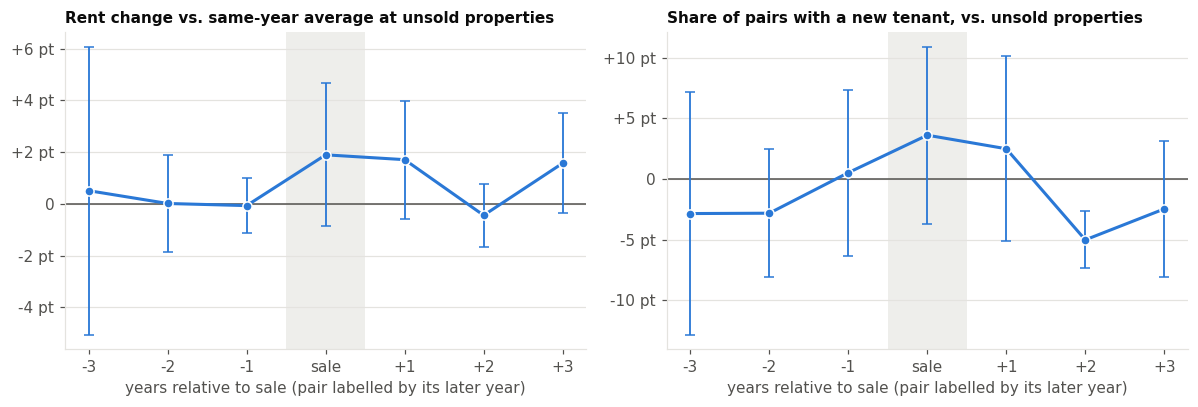

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in [
    (ax1, "excess_change", "Rent change vs. same-year average at unsold properties"),
    (ax2, "excess_new_tenancy", "Share of pairs with a new tenant, vs. unsold properties"),
]:
    m, se = event_table[col] * 100, event_table[f"{col}_se"] * 100
    ax.axhline(0, color=INK_2, lw=1)
    ax.axvspan(-0.5, 0.5, color=GRID, alpha=0.6, lw=0)
    ax.errorbar(m.index, m.values, yerr=1.96 * se.values, color=SERIES[0], lw=2, marker="o", ms=6,
                markeredgecolor="white", markeredgewidth=1, capsize=3, elinewidth=1.2)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(m.index, [f"{t:+d}" if t else "sale" for t in m.index])
    ax.set_xlabel("years relative to sale (pair labelled by its later year)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f} pt" if v else "0")
fig.tight_layout()

In [33]:
# pooled before / at / after, with the same property-level averaging
per_prop = per_prop.reset_index()
per_prop["period"] = pd.cut(per_prop["event_time"], [-4, -1, 0, 3], labels=["before (−3…−1)", "sale year (0)", "after (+1…+3)"])
pooled = per_prop.groupby("period", observed=True).agg(
    property_years=("chg", "size"),
    mean_change=("chg", "mean"),
    excess_change=("excess_chg", "mean"),
    new_tenancy=("new_tenancy", "mean"),
    excess_new_tenancy=("excess_new_tenancy", "mean"),
)
pooled.style.format({c: ("{:,.0f}" if c == "property_years" else "{:+.1%}" if "excess" in c else "{:.1%}") for c in pooled.columns})

,property_years,mean_change,excess_change,new_tenancy,excess_new_tenancy
period,,,,,
before (−3…−1),92,2.5%,+0.1%,7.8%,-1.1%
sale year (0),43,3.9%,+1.9%,11.9%,+3.6%
after (+1…+3),88,3.7%,+1.0%,6.9%,-1.0%


## 9. Building permits: overlap with the registry

There are two Culver City permit sources in `contractor_search/data/raw`. Both are opened **read-only**.

| source | coverage | key fields |
|---|---|---|
| `permits.db`, city = Culver City (city ArcGIS open-data layer, backed by Accela) | 21,015 permits, opened mostly 2020 – Mar 2026 | permit number, type, status, opened date, structured street address, work description |
| `culver_city_permits_2025_to_2026-08-15_partial.db` (full-detail Accela extract) | 5,861 permits, Jan 2025 – Aug 2026 | adds **parcel number (APN)**, owner, contractor, valuation, residential/commercial |

The two are combined on permit number. The open-data record is used when a permit is in both, and the extract adds ~1,900 permits after March 2026.

**Matching to registry properties.** A property is identified by a normalized street address: street number + street name, with standard suffixes (AVENUE → AVE, …) and no leading or trailing direction (`W WASHINGTON BLVD` → `WASHINGTON BLVD`, `CANTERBURY DR NE` → `CANTERBURY DR`). Unit designators are ignored. Two further rules apply:
- **Duplex lots.** Some registry lots list neighbouring street numbers as units (e.g. `10799 NORTHGATE ST` with units 10797 and 10799). Those numbers are added as aliases. Ordinary apartment numbers like `101` are not, because they would collide with real addresses.
- **Parcel fallback.** Permits in the full-detail extract are also matched by APN when the address fails, e.g. a misspelt street name (`PIGOTT` vs `PIGGOTT`). Where both methods match, they agree on the same property 96% of the time.

In [34]:
import json
import sqlite3

PERMIT_DIR = Path("/Users/adamswietek/Documents/contractor_search/data/raw")


def read_sqlite(db, query):
    con = sqlite3.connect(f"file:{PERMIT_DIR / db}?mode=ro", uri=True)  # read-only
    try:
        return pd.read_sql(query, con)
    finally:
        con.close()


open_data = read_sqlite(
    "permits.db",
    "select permit_number, permit_type, permit_subtype, status, applied_date, work_description, raw_json "
    "from permits where city = 'Culver City'",
)
fields = open_data.pop("raw_json").map(json.loads)
open_data["street_number"] = fields.map(lambda r: r.get("USER_StreetNumber"))
open_data["street_name"] = fields.map(lambda r: r.get("USER_StreetName"))
open_data["date"] = pd.to_datetime(open_data["applied_date"], errors="coerce")

detail = read_sqlite(
    "culver_city_permits_2025_to_2026-08-15_partial.db",
    "select p.record_number as permit_number, p.record_type as permit_type, p.record_status as status, "
    "p.permit_date, p.work_location_address, p.permit_category, p.project_description, "
    "p.contractor_valuation, pa.parcel_number "
    "from permits p "
    "left join permit_parcels pp on pp.permit_id = p.id "
    "left join parcels pa on pa.id = pp.parcel_id",
)
detail["date"] = pd.to_datetime(detail["permit_date"], errors="coerce")

print(f"open data: {len(open_data):,} permits, opened {open_data['date'].min():%Y-%m-%d} → {open_data['date'].max():%Y-%m-%d}")
print(f"full-detail extract: {detail['permit_number'].nunique():,} permits, {detail['date'].min():%Y-%m-%d} → {detail['date'].max():%Y-%m-%d}, "
      f"{detail.groupby('permit_number')['parcel_number'].first().notna().mean():.0%} with a parcel number, "
      f"{detail['permit_number'].drop_duplicates().isin(set(open_data['permit_number'])).mean():.0%} also in open data")

open data: 21,015 permits, opened 1999-05-21 → 2026-03-05
full-detail extract: 5,861 permits, 2025-01-01 → 2026-08-14, 89% with a parcel number, 68% also in open data


In [35]:
SUFFIX = {"AVENUE": "AVE", "AV": "AVE", "BOULEVARD": "BLVD", "STREET": "ST", "DRIVE": "DR", "PLACE": "PL", "LANE": "LN",
          "ROAD": "RD", "CIRCLE": "CIR", "COURT": "CT", "PARKWAY": "PKWY", "TERRACE": "TER", "WY": "WAY"}
DIRECTIONS = {"N", "S", "E", "W", "NE", "NW", "SE", "SW"}


def address_key(number, street):
    # "10032 S CULVER BLVD" -> "10032 CULVER BLVD"
    if pd.isna(number) or pd.isna(street):
        return np.nan
    words = [SUFFIX.get(w, w) for w in re.sub(r"[^A-Z0-9 ]", " ", str(street).upper()).split()]
    while len(words) > 1 and words[0] in DIRECTIONS:
        words = words[1:]
    while len(words) > 1 and words[-1] in DIRECTIONS:
        words = words[:-1]
    num = re.match(r"\d+", str(number).strip())
    return f"{int(num.group())} {' '.join(words)}" if num else np.nan


def split_address(address):
    # "11160 WASHINGTON BLVD, Unit C, CULVER CITY CA 90232" -> ("11160", "WASHINGTON BLVD")
    a = re.sub(UNIT_DESIGNATOR, "", str(address).upper().split(",")[0])
    m = re.match(r"\s*(\d+)(?:\s*1/2)?\s+(.*)", a)
    return (m.group(1), m.group(2)) if m else (np.nan, np.nan)


def property_key(address):
    return address_key(*split_address(address))


digits = lambda s: s.astype("string").str.replace(r"\D", "", regex=True).replace("", pd.NA)

# registry side: every registered address (incl. those without rent records), plus duplex aliases
reg_addr = everything[["address", "unit_number", "parcel"]].drop_duplicates().copy()
reg_addr[["num", "street"]] = pd.DataFrame([split_address(a) for a in reg_addr["address"]], index=reg_addr.index)
reg_addr["prop"] = [address_key(n, s) for n, s in zip(reg_addr["num"], reg_addr["street"])]
unit_no = pd.to_numeric(reg_addr["unit_number"].where(reg_addr["unit_number"].fillna("").str.fullmatch(r"\d{3,6}")), errors="coerce")
street_no = pd.to_numeric(reg_addr["num"], errors="coerce")
is_duplex = unit_no.notna() & (unit_no.astype("Int64").astype(str).str.len() == street_no.astype("Int64").astype(str).str.len()) \
            & (unit_no - street_no).abs().le(20)
aliases = pd.concat([
    reg_addr.assign(key=reg_addr["prop"])[["key", "prop"]],
    reg_addr[is_duplex].assign(key=[address_key(u, s) for u, s in zip(reg_addr.loc[is_duplex, "unit_number"], reg_addr.loc[is_duplex, "street"])])[["key", "prop"]],
]).dropna().drop_duplicates()
key_to_prop = aliases.drop_duplicates("key").set_index("key")["prop"]
apn_to_prop = reg_addr.assign(apn=digits(reg_addr["parcel"])).dropna(subset=["apn", "prop"]).drop_duplicates("apn").set_index("apn")["prop"]

# permit side: one row per permit number, open-data record first
open_data["key"] = [address_key(n, s) for n, s in zip(open_data["street_number"], open_data["street_name"])]
detail["key"] = [property_key(a) for a in detail["work_location_address"]]
detail["apn_prop"] = digits(detail["parcel_number"]).map(apn_to_prop)
detail_one = detail.groupby("permit_number").agg(
    key=("key", "first"), apn_prop=("apn_prop", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
    date=("date", "first"), permit_type=("permit_type", "first"), status=("status", "first"),
    category=("permit_category", "first"), valuation=("contractor_valuation", "first"),
    work_description=("project_description", "first"),
)
permits = pd.concat([
    open_data.assign(source="open data")[["permit_number", "source", "date", "key", "permit_type", "status", "work_description"]],
    detail_one[~detail_one.index.isin(set(open_data["permit_number"]))].reset_index().assign(source="full-detail only")
    [["permit_number", "source", "date", "key", "permit_type", "status", "work_description"]],
], ignore_index=True)
for col in ["apn_prop", "category", "valuation"]:
    permits[col] = permits["permit_number"].map(detail_one[col])
permits["category"] = permits["category"].replace("", np.nan)
permits["year"] = permits["date"].dt.year

by_address = permits["key"].map(key_to_prop)
permits["prop"] = by_address.fillna(permits["apn_prop"])
permits["match"] = np.select([by_address.notna(), permits["apn_prop"].notna()], ["address", "parcel only"], "none")

rent_props = set(panel["address"].map(property_key).dropna())
permits["rental"] = permits["prop"].isin(rent_props)

both = permits.dropna(subset=["apn_prop"]).assign(by_addr=lambda d: d["key"].map(key_to_prop)).dropna(subset=["by_addr"])
print(f"{len(permits):,} permits | matched by address {permits['match'].eq('address').sum():,}, by parcel only "
      f"{permits['match'].eq('parcel only').sum()}, unmatched {permits['match'].eq('none').sum():,}")
print(f"address vs parcel agreement where both match: {both['by_addr'].eq(both['apn_prop']).mean():.0%} of {len(both):,}")
print(f"registry: {reg_addr['prop'].nunique():,} properties ({len(rent_props):,} with rent records), "
      f"{aliases['key'].nunique() - reg_addr['prop'].nunique()} duplex alias addresses")

22,891 permits | matched by address 7,709, by parcel only 75, unmatched 15,107
address vs parcel agreement where both match: 97% of 1,095
registry: 3,284 properties (2,491 with rent records), 739 duplex alias addresses


### How much do they overlap?

**From the permit side.** What share of permits are at registry properties, by year and by permit category? Only the full-detail extract carries the residential/commercial category.

In [36]:
in_window = permits[permits["year"].between(2019, 2026)]
overlap_by_year = in_window.groupby("year").agg(
    permits=("permit_number", "size"),
    at_registry_property=("prop", lambda s: s.notna().sum()),
    at_rental_property=("rental", "sum"),
    rental_properties=("prop", lambda s: s[in_window.loc[s.index, "rental"]].nunique()),
)
overlap_by_year["share_at_rental"] = overlap_by_year["at_rental_property"] / overlap_by_year["permits"]
display(overlap_by_year.style.format("{:,.0f}").format("{:.0%}", subset=["share_at_rental"]))

by_category = permits.dropna(subset=["category"]).groupby("category").agg(
    permits=("permit_number", "size"), share_at_rental=("rental", "mean"))
display(by_category.style.format({"permits": "{:,.0f}", "share_at_rental": "{:.0%}"}))

by_type = permits.groupby("permit_type").agg(permits=("permit_number", "size"), share_at_rental=("rental", "mean"))
by_type.sort_values("permits", ascending=False).head(10).style.format({"permits": "{:,.0f}", "share_at_rental": "{:.0%}"})

,permits,at_registry_property,at_rental_property,rental_properties,share_at_rental
year,,,,,
2019,504,145,85,52,17%
2020,"1,283",376,244,96,19%
2021,"3,289","1,037",805,256,24%
2022,"3,610","1,141",922,284,26%
2023,"4,268","1,723","1,395",542,33%
2024,"3,438","1,164",938,390,27%
2025,"3,579","1,248","1,021",311,29%
2026,"2,282",816,712,205,31%


,permits,share_at_rental
category,,
Commercial,984,4%
Mixed-Use,26,8%
Residential,"4,174",36%


,permits,share_at_rental
permit_type,,
Electrical,"7,665",31%
Build,"6,656",23%
Plumbing,"3,944",26%
Mechanical,"3,212",24%
Building,616,21%
PROGRAM,463,70%
Demo,246,19%
Solar Residential Streamlined,47,9%
Soft Story,19,79%


**From the registry side.** What share of rental properties (addresses with rent records) have at least one permit opened in 2019–2026? The table breaks this down by building size, by the tenure samples from section 7, and by whether the property was sold (section 8). `PROGRAM` permits are soft-story (SWOF) seismic-retrofit tracking records, which are mostly for multi-unit rental buildings.

In [37]:
SOFT_STORY = {"PROGRAM", "Soft Story", "Soft Weak Open-Face Tracking"}

units_prop = panel[["unit_id", "address"]].drop_duplicates().assign(prop=lambda d: d["address"].map(property_key)).dropna(subset=["prop"])
rental_props = units_prop.groupby("prop").agg(units=("unit_id", "nunique"))
rp = in_window[in_window["rental"]]
rental_props["permits"] = rp.groupby("prop").size().reindex(rental_props.index, fill_value=0)
rental_props["soft_story"] = rp[rp["permit_type"].isin(SOFT_STORY)].groupby("prop").size().reindex(rental_props.index, fill_value=0).gt(0)
rental_props["size"] = pd.cut(rental_props["units"], [0, 1, 4, 9, np.inf], labels=["1 unit", "2–4", "5–9", "10+"])
rental_props["sample"] = units_prop.join(tenure["sample"], on="unit_id").groupby("prop")["sample"].agg(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
rental_props["sold"] = rental_props.index.isin(set(sales["address"].map(property_key).dropna()))


def coverage(g):
    return pd.Series({
        "properties": len(g),
        "units": g["units"].sum(),
        "with_permit": g["permits"].gt(0).mean(),
        "units_covered": g.loc[g["permits"].gt(0), "units"].sum() / g["units"].sum(),
        "median_permits_if_any": g.loc[g["permits"].gt(0), "permits"].median(),
        "soft_story": g["soft_story"].mean(),
    })


cov = pd.concat({
    "all": coverage(rental_props).to_frame("rental properties").T,
    "size": rental_props.groupby("size", observed=True).apply(coverage),
    "sample (section 7)": rental_props.groupby("sample").apply(coverage).reindex(SAMPLES + ["new construction"]).dropna(how="all"),
    "sold (section 8)": rental_props.groupby(rental_props["sold"].map({True: "sold", False: "not sold"})).apply(coverage),
})
cov.style.format({"properties": "{:,.0f}", "units": "{:,.0f}", "with_permit": "{:.0%}", "units_covered": "{:.0%}",
                  "median_permits_if_any": "{:.0f}", "soft_story": "{:.0%}"})

/var/folders/7b/rl6lkdns1dbfv_n3wwwmq8580000gn/T/ipykernel_51312/4151507568.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "size": rental_props.groupby("size", observed=True).apply(coverage),
/var/folders/7b/rl6lkdns1dbfv_n3wwwmq8580000gn/T/ipykernel_51312/4151507568.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "sample (section 7)": rental_props.groupby("sample").apply(coverage).reindex(SAMPLES + ["new 

In [38]:
# what kind of work shows up at rental properties
rental_permits = in_window[in_window["rental"]]
display(rental_permits["permit_type"].value_counts().rename("permits").to_frame().T)
rental_permits.loc[rental_permits["work_description"].notna(), ["permit_number", "date", "prop", "permit_type", "work_description"]] \
    .sample(8, random_state=4).assign(work_description=lambda d: d["work_description"].str[:110])

permit_type,Electrical,Build,Plumbing,Mechanical,PROGRAM,Building,Demo,Soft Story,Electric Vehicle Service Equip,Solar Residential Streamlined,Soft Weak Open-Face Tracking
permits,2322,1522,995,756,324,132,44,15,7,4,1


,permit_number,date,prop,permit_type,work_description
16086,E25-0061,2025-01-27,5625 WINDSOR WAY,Electrical,KITCHEN SINK REPLACEMENT AND ELECTRI...
6385,B21-0306,2021-04-27,3430 CAROLINE AVE,Build,NEW SINGLE CAR GARAGE DOOR TO BE INS...
21577,B26-0494,2026-06-15,10920 ALETTA AVE,Building,Replace handrails & guardrails at ex...
18969,E23-0754,2023-08-11,6575 GREEN VALLEY CIR,Electrical,Install (1) panel up to 200 A
381,M24-0382,2024-10-25,10204 BRADDOCK DR,Mechanical,mechanical for DETACHED ADU ABV GARA...
13884,P24-0008,2024-01-08,4828 HOLLOW CORNER RD,Plumbing,Non structural remodel of two bathro...
14558,E22-0464,2022-04-26,5007 STONEY CREEK RD,Electrical,1 service sub panel
21921,E26-0318,2026-04-13,4114 BALDWIN AVE,Electrical,Electrical for New (4) unit multifam...


## 10. Major permits: do rents change after the work?

**Permit groups.** These come from the contractor-search project's vocabulary (`contractor_search/config/scope_vocabulary.json`). It defines seven groups by regex patterns on the work description: roof replacement, electrical panel upgrade, kitchen remodel, ADU, HVAC, foundation and seismic retrofit. The app's precomputed matches (`scope_matches` in `contractor_search.duckdb`) cover only the 2025–26 extract, so the same patterns are re-applied here to every permit from 2019 on. Following the app, the description is lowercased and punctuation is turned into spaces. Where a permit has both an open-data and an extract description, both are searched. On the extract's permits this reproduces 99% of the app's matches.

**Which permits count.** Only **direct** pattern matches are used. The looser "related" patterns are ignored, e.g. any mention of "200 amp" for panel upgrades. Void, withdrawn, not-approved and incomplete permits are dropped, as are soft-story `PROGRAM` records, which only track that a building is on the retrofit list; the actual retrofit permits are kept.

**Design** (same as section 8):
- **Event.** A property's **first** qualifying permit in each group, dated by when it was opened.
- **Event time 0.** The year of the first rent registration at that property after the permit was opened. So the event-0 pair runs from the last rent before the permit to the first rent after it.
- **Comparison group.** Units at rental properties with **no major permit of any group** in 2019–2026. New construction is excluded from both sides. Each pair is compared with that group's same-year average change (`excess`) and same-year share of new tenancies.
- **Uncertainty.** Averages are taken per property, then across properties, and the ±95% bands are computed across properties.
- **Whole property is treated.** A permit is assigned to the whole property, so work on one unit (e.g. a kitchen remodel in unit 3) is spread over every unit in the building. That dilutes unit-level effects in multi-unit buildings, so results are also shown for single-unit properties alone.

In [39]:
VOCAB = json.load(open("/Users/adamswietek/Documents/contractor_search/config/scope_vocabulary.json"))
SCOPE_LABELS = {s["id"]: s["label"] for s in VOCAB["scopes"]}
DEAD_STATUS = {"Void", "Withdrawn", "Wtihdrawn", "Not Approved", "Application Incomplete", "No Retro-Fit - Emailed"}


def search_text(t):
    # same normalization as the contractor-search app
    return " ".join(re.sub(r"[^a-z0-9]+", " ", t.casefold()).split()) if isinstance(t, str) else ""


text = (permits["work_description"].map(search_text) + " | "
        + permits["permit_number"].map(detail.drop_duplicates("permit_number").set_index("permit_number")["project_description"]).map(search_text))
counts = permits["status"].isin(DEAD_STATUS).eq(False) & permits["permit_type"].ne("PROGRAM")
for scope in VOCAB["scopes"]:
    patterns = [re.compile(p, re.IGNORECASE) for p in scope["direct_patterns"]]
    permits[scope["id"]] = text.map(lambda t: any(p.search(t) for p in patterns)) & counts
SCOPES = list(SCOPE_LABELS)

eligible = rental_props.index[rental_props["sample"].ne("new construction")]
major = permits[permits["prop"].isin(eligible) & permits["year"].between(2019, 2026)]
first_permit = {s: major[major[s]].groupby("prop")["date"].min() for s in SCOPES}
first_permit["any"] = major[major[SCOPES].any(axis=1)].groupby("prop")["date"].min()
SCOPE_LABELS["any"] = "Any major permit"
SHORT = {"roof_replacement": "Roof", "panel_upgrade": "Panel upgrade", "kitchen_remodel": "Kitchen remodel", "adu": "ADU",
         "hvac": "HVAC", "foundation": "Foundation", "seismic": "Seismic retrofit", "any": "Any major permit"}

pd.DataFrame({
    SCOPE_LABELS[s]: {
        "permits": int(major[s].sum()) if s != "any" else int(major[SCOPES].any(axis=1).sum()),
        "properties": len(d),
        "units": int(rental_props.loc[d.index, "units"].sum()),
        "single-unit properties": int(rental_props.loc[d.index, "size"].eq("1 unit").sum()),
        "first permit 2020–25": int(d.dt.year.between(2020, 2025).sum()),
    } for s, d in first_permit.items()
}).T.sort_values("properties", ascending=False)

,permits,properties,units,single-unit properties,first permit 2020–25
Any major permit,1501,581,2667,259,525
Roof replacement,221,184,1285,74,164
Electrical panel upgrade,207,145,401,95,139
Accessory dwelling unit (ADU),429,125,343,44,114
Seismic retrofit,152,106,621,21,85
Kitchen remodel,388,88,452,40,77
HVAC replacement or installation,133,76,340,35,66
Foundation work,26,20,88,5,20


In [40]:
unit_prop = units_prop.set_index("unit_id")["prop"]
reg_dates = panel.assign(prop=panel["unit_id"].map(unit_prop)).groupby("prop")["rent_date"].apply(np.sort)
pairs_p = yoy.assign(prop=yoy["unit_id"].map(unit_prop), new_tenancy=yoy["tenancy"].eq("new tenancy"))
pairs_p = pairs_p[pairs_p["prop"].isin(eligible)]
pairs_p["single_unit"] = pairs_p["prop"].map(rental_props["size"]).eq("1 unit")

controls = pairs_p[~pairs_p["prop"].isin(first_permit["any"].index)]
base_chg = controls.groupby("year")["chg"].mean()
base_nt = controls.groupby("year")["new_tenancy"].mean()
base_chg_same = controls[controls["tenancy"].eq("same tenancy")].groupby("year")["chg"].mean()
print(f"comparison group: {controls['prop'].nunique():,} properties, {controls['unit_id'].nunique():,} units, {len(controls):,} pairs")


def event_year(prop, date):
    # year of the property's first rent registration after the permit was opened
    later = reg_dates.get(prop, np.array([], dtype="datetime64[ns]"))
    later = later[later > np.datetime64(date)]
    return pd.Timestamp(later[0]).year if len(later) else date.year + 1


def event_pairs(scope, window=3):
    starts = first_permit[scope]
    ev_year = pd.Series({p: event_year(p, d) for p, d in starts.items()}, dtype="Int64")
    e = pairs_p[pairs_p["prop"].isin(starts.index)].copy()
    e["event_time"] = (e["year"] - e["prop"].map(ev_year)).astype(int)
    e = e[e["event_time"].between(-window, window)]
    e["excess_chg"] = e["chg"] - e["year"].map(base_chg)
    e["excess_new_tenancy"] = e["new_tenancy"] - e["year"].map(base_nt)
    e["excess_chg_same"] = (e["chg"] - e["year"].map(base_chg_same)).where(e["tenancy"].eq("same tenancy"))
    return e


def by_property(e, cols=("excess_chg", "excess_new_tenancy", "excess_chg_same")):
    return e.groupby(["event_time", "prop"])[list(cols)].mean()


events = {s: event_pairs(s) for s in first_permit}

comparison group: 1,625 properties, 4,344 units, 16,124 pairs


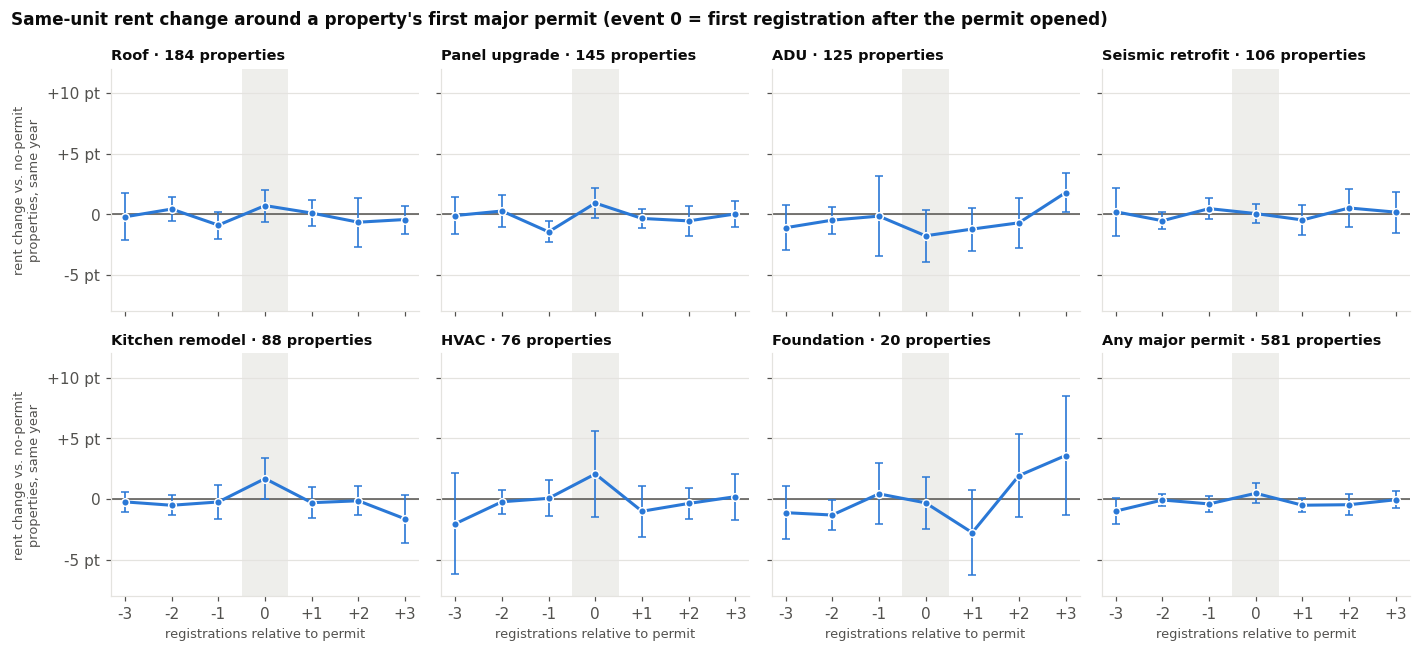

In [41]:
order = sorted(SCOPES, key=lambda s: -len(first_permit[s])) + ["any"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, s in zip(axes.flat, order):
    g = by_property(events[s])["excess_chg"].groupby("event_time")
    m, se = g.mean() * 100, g.sem() * 100
    ax.axhline(0, color=INK_2, lw=1)
    ax.axvspan(-0.5, 0.5, color=GRID, alpha=0.6, lw=0)
    ax.errorbar(m.index, m.values, yerr=1.96 * se.values, color=SERIES[0], lw=2, marker="o", ms=5,
                markeredgecolor="white", markeredgewidth=1, capsize=2.5, elinewidth=1.1)
    ax.set_title(f"{SHORT[s]} · {len(first_permit[s])} properties", fontsize=9.5)
    ax.set_xticks(range(-3, 4), ["-3", "-2", "-1", "0", "+1", "+2", "+3"])
for ax in axes[-1]:
    ax.set_xlabel("registrations relative to permit", fontsize=8.5)
for ax in axes[:, 0]:
    ax.set_ylabel("rent change vs. no-permit\nproperties, same year", fontsize=8.5)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f} pt" if v else "0")
ax.set_ylim(-8, 12)
fig.suptitle("Same-unit rent change around a property's first major permit (event 0 = first registration after the permit opened)",
             x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
fig.tight_layout()

**Pooled before / at / after.** Event times are grouped as before (−3…−1), the permit year (0) and after (+1…+3). The table shows excess rent change for all pairs and for **sitting tenants only**, the excess share of new tenancies, and the same numbers for single-unit properties, where whole-property treatment is exact. ± is one standard error across properties.

In [42]:
PERIODS = pd.cut(pd.Series(range(-3, 4), index=range(-3, 4)), [-4, -1, 0, 3], labels=["before", "at", "after"])


def pooled(e, col):
    p = e.assign(period=e["event_time"].map(PERIODS)).groupby(["period", "prop"], observed=True)[col].mean().dropna()
    g = p.groupby("period", observed=True)
    return g.mean(), g.sem(), g.size()


rows_ = []
for s in order:
    e = events[s]
    row = {"group": SHORT[s], "properties": len(first_permit[s])}
    for label, frame, col in [("rent", e, "excess_chg"), ("rent, sitting tenants", e, "excess_chg_same"),
                              ("new tenancy", e, "excess_new_tenancy"),
                              ("rent, single-unit", e[e["single_unit"]], "excess_chg")]:
        m, se, n = pooled(frame, col)
        for period in ["before", "at", "after"]:
            row[(label, period)] = f"{m.get(period, np.nan) * 100:+.1f} ± {se.get(period, np.nan) * 100:.1f}" if period in m else "–"
    rows_.append(row)
pooled_table = pd.DataFrame(rows_).set_index(["group", "properties"])
pooled_table.columns = pd.MultiIndex.from_tuples(pooled_table.columns)
pooled_table

rent                         rent, sitting tenants                         new tenancy                          rent, single-unit                        
                                 before          at       after                before          at       after      before           at       after            before          at       after
group            properties                                                                                                                                                                 
Roof             184         -0.3 ± 0.6  +0.7 ± 0.7  -0.3 ± 0.4            -0.1 ± 0.7  -0.0 ± 0.7  -0.5 ± 0.5  -0.9 ± 2.0   +2.7 ± 2.6  -2.0 ± 1.3        -1.0 ± 1.1  +1.2 ± 1.3  +0.6 ± 0.8
Panel upgrade    145         -0.5 ± 0.4  +0.9 ± 0.6  -0.5 ± 0.3            -0.2 ± 0.3  +0.3 ± 0.5  -0.6 ± 0.3  +0.8 ± 2.2   +2.4 ± 3.2  -4.3 ± 1.0        -1.0 ± 0.6  +0.8 ± 0.7  -0.7 ± 0.4
ADU              125         -1.3 ± 0.8  -1.8 ± 1.1  -1.0 ± 0.6            -0.8 ± 0.5  -2.1 ± 1.2  -0.8 ± 0.6  +1.2 ± 2.9   -3.2 ± 2.8  +1.1 ± 2.8        -3.1 ± 2.2  -0.7 ± 0.6  +0.2 ± 0.8
Seismic retrofit 106         +0.2 ± 0.5  +0.1 ± 0.4  -0.2 ± 0.4            +0.5 ± 0.6  -0.2 ± 0.4  -0.5 ± 0.7  -0.2 ± 1.9   +2.8 ± 3.2  -1.5 ± 2.0        -0.9 ± 1.0  -3.2 ± 2.7  -1.7 ± 1.1
Kitchen remodel  88          -0.2 ± 0.5  +1.7 ± 0.9  -0.7 ± 0.4            +0.2 ± 0.6  +1.1 ± 0.8  -0.5 ± 0.4  +6.7 ± 4.1   +0.4 ± 3.8  -0.0 ± 1.7        -0.1 ± 1.5  +5.9 ± 4.9  -1.9 ± 0.3
HVAC             76          -0.5 ± 0.7  +2.1 ± 1.8  -0.7 ± 0.6            -0.6 ± 0.7  +1.0 ± 1.7  -0.6 ± 0.6  +4.7 ± 3.4   +1.4 ± 4.1  +7.3 ± 4.1        -1.2 ± 1.7  +5.6 ± 5.4  -2.2 ± 1.0
Foundation       20          -0.7 ± 0.4  -0.3 ± 1.1  -0.4 ± 0.6            -0.6 ± 0.3  -1.1 ± 1.1  +0.8 ± 1.1  -5.0 ± 2.4  +3.0 ± 10.0  +2.3 ± 5.7        -1.6 ± 0.1  -4.3 ± 3.8  +0.2 ± 1.3
Any major permit 581         -0.4 ± 0.3  +0.5 ± 0.4  -0.6 ± 0.2            -0.2 ± 0.3  -0.2 ± 0.4  -0.4 ± 0.2  +1.6 ± 1.2   +1.6 ± 1.5  -1.4 ± 0.9        -1.0 ± 0.5  +1.4 ± 0.8  -0.5 ± 0.3

## 11. Single-family ADUs: do they come online as registered rentals?

**Question.** When a single-family lot builds an ADU, does a new rental unit, with a rent, appear in the registry afterwards?

**Pieces.**
- **ADU permits.** Building permits matching the ADU group from section 10 (direct matches, not void or withdrawn), with one lot per property and its first ADU permit. The ADU counts as **completed** when a permit on the lot is `Finaled`. The completion date is the permit's status date in the open-data layer.
- **Single-family lots.** These come from the LA County Assessor parcel file (`contractor_search/data/LACounty_Parcels.gdb`, 2023 roll), read **read-only** and without geometry. A lot is single-family detached when its use code starts with `01` and isn't a condo (`…C`). A **homeowner's exemption** on the parcel means the owner lives in the main house. Parcels are matched to permits by normalized address.
- **Linking registry records to lots.** Records are linked by normalized address, or by parcel number when the ADU is registered under its own street number.
- **When a unit comes online.** The registry gives every unit a 6/11/2019 base-rent row, even units built years later, sometimes holding the unit's *current* rent. So each unit is dated by its **first registration after the base row**. A unit is **new** when that date falls after the ADU permit was opened.
- **Which new unit is the ADU.** Registries label ADUs inconsistently (`A`, `4297A`, `UNIT A`, `3842.5`, `1/2` …). A new unit counts as the ADU if its label looks like one. On lots with no such label, a new unit with at most one bedroom counts instead.
- **Enough time.** Only ADUs completed by **mid-2025** are counted, so each had at least one registration cycle (the mid-2026 one) in which to appear.

In [43]:
import pyogrio

PARCELS_GDB = "/Users/adamswietek/Documents/contractor_search/data/LACounty_Parcels.gdb"
parcels = pyogrio.read_dataframe(
    PARCELS_GDB, layer="LACounty_Parcels", read_geometry=False, where="TaxRateCity = 'CULVER CITY'",
    columns=["AIN", "TaxRateCity", "SitusHouseNo", "SitusStreet", "SitusUnit", "UseCode", "UseDescription", "Units1",
             "YearBuilt1", "Roll_Year", "Roll_HomeOwnersExemp"],  # the where-filter field must be among the columns read
)
assert len(parcels), "parcel read returned no rows"
parcels["key"] = [address_key(n, s) for n, s in zip(parcels["SitusHouseNo"], parcels["SitusStreet"])]
parcels["single_family"] = parcels["UseCode"].str.startswith("01") & ~parcels["UseCode"].str.endswith("C")
parcels["owner_occupied"] = pd.to_numeric(parcels["Roll_HomeOwnersExemp"], errors="coerce").gt(0)
parcel_by_key = parcels.dropna(subset=["key"]).sort_values("SitusUnit", na_position="first").drop_duplicates("key").set_index("key")
print(f"{len(parcels):,} Culver City parcels (roll {parcels['Roll_Year'].mode()[0]}): "
      f"{parcels['single_family'].sum():,} single-family detached, {parcels['owner_occupied'].mean():.0%} with a homeowner's exemption")

status_date = read_sqlite("permits.db", "select permit_number, status_date from permits where city = 'Culver City'") \
    .set_index("permit_number")["status_date"]
adu_permits = permits[permits["adu"] & permits["permit_type"].isin(["Build", "Building"])].copy()
adu_permits["final_date"] = pd.to_datetime(adu_permits["permit_number"].map(status_date), errors="coerce") \
    .where(adu_permits["status"].eq("Finaled"))
adu_permits["lot"] = adu_permits["key"].map(key_to_prop).fillna(adu_permits["key"])

adu_lots = adu_permits.sort_values("date").groupby("lot").agg(
    key=("key", "first"), opened=("date", "first"), final_date=("final_date", "min"))
adu_lots = adu_lots.join(parcel_by_key[["UseCode", "UseDescription", "single_family", "owner_occupied"]], on="key")
adu_lots["completed_by_mid_2025"] = adu_lots["final_date"].le("2025-06-30")
print(f"ADU lots: {len(adu_lots)} | matched to a parcel: {adu_lots['UseCode'].notna().sum()} | "
      f"single-family detached: {adu_lots['single_family'].eq(True).sum()} | "
      f"of those completed (finaled): {(adu_lots['single_family'].eq(True) & adu_lots['final_date'].notna()).sum()}, "
      f"by mid-2025: {(adu_lots['single_family'].eq(True) & adu_lots['completed_by_mid_2025']).sum()}")
adu_lots["UseDescription"].fillna("(no parcel match)").value_counts().to_frame("ADU lots").T

13,661 Culver City parcels (roll 2023): 6,889 single-family detached, 46% with a homeowner's exemption
ADU lots: 605 | matched to a parcel: 556 | single-family detached: 462 | of those completed (finaled): 259, by mid-2025: 227


UseDescription,Single,Two Units,(no parcel match),Three Units (Any Combination),Five or more apartments,Four Units (Any Combination),Store Combination
ADU lots,463,61,49,11,10,10,1


In [44]:
BASE_DATE = pd.Timestamp("2019-06-11")
ADU_LABEL = r"(?:^|\d|\s|#)(?:A|B)$|ADU|REAR|BACK|GUEST|\.5$|1/2|^UNIT A$"

sf_lots = adu_lots[adu_lots["single_family"].eq(True)].copy()
sf_lots["ain"] = sf_lots["key"].map(parcel_by_key["AIN"])
ain_to_lot = sf_lots.dropna(subset=["ain"]).reset_index().drop_duplicates("ain").set_index("ain")["lot"]


def lot_of(frame):
    # registry record -> ADU lot, by address, else by parcel (an ADU can be registered under its own street number)
    by_address = frame["address"].map(property_key)
    by_parcel = digits(frame["parcel"]).astype("string").map(ain_to_lot)
    return by_address.where(by_address.isin(sf_lots.index), by_parcel)


lot_rows = df.assign(lot=lot_of(df))
lot_rows = lot_rows[lot_rows["lot"].isin(sf_lots.index) & (lot_rows["rent_date"] > BASE_DATE)].sort_values("rent_date")

adu_units = lot_rows.groupby("unit_id").agg(
    lot=("lot", "first"), unit=("unit_number", "last"), bedrooms=("bedrooms", "last"), status=("unit_status", "last"),
    lease_start=("lease_start", "last"), first_registered=("rent_date", "first"))
first_rent = lot_rows.dropna(subset=["rent_clean"]).groupby("unit_id")[["rent_date", "rent_clean"]].first()
adu_units = adu_units.join(first_rent.rename(columns={"rent_date": "first_rent_date", "rent_clean": "first_rent"}))
adu_units = adu_units.join(sf_lots[["opened", "final_date"]], on="lot")
adu_units["new"] = adu_units["first_registered"] > adu_units["opened"]
adu_units["adu_label"] = adu_units["unit"].fillna("").str.upper().str.strip().str.contains(ADU_LABEL)
labelled_lot = adu_units[adu_units["new"] & adu_units["adu_label"]].groupby("lot").size()
adu_units["is_adu"] = adu_units["new"] & (
    adu_units["adu_label"] | (~adu_units["lot"].isin(labelled_lot.index) & adu_units["bedrooms"].le(1)))

per_lot = adu_units.groupby("lot").agg(existing=("new", lambda s: (~s).sum()), new=("new", "sum"), adu=("is_adu", "sum"))
sf_lots = sf_lots.join(per_lot).fillna({"existing": 0, "new": 0, "adu": 0})
registered_no_units = set(lot_of(no_rent).dropna())
sf_lots["outcome"] = np.select(
    [sf_lots["adu"] > 0, sf_lots["new"] > 0, sf_lots["existing"] > 0, sf_lots.index.isin(registered_no_units)],
    ["ADU registered", "other new unit registered", "no new unit (lot was already a rental)", "registered, no rental unit declared"],
    default="lot not in registry",
)
done = sf_lots[sf_lots["completed_by_mid_2025"]]
outcomes = pd.crosstab(done["owner_occupied"].map({True: "owner lives on lot (homeowner's exemption)", False: "no homeowner's exemption"}),
                       done["outcome"], margins=True, margins_name="all")
outcomes = outcomes.reindex(columns=["ADU registered", "other new unit registered", "no new unit (lot was already a rental)",
                                     "registered, no rental unit declared", "lot not in registry", "all"], fill_value=0)
display(outcomes)
print(f"share of completed single-family ADUs with a registered ADU rent: {done['outcome'].eq('ADU registered').mean():.0%} "
      f"(by completion year: {done.groupby(done['final_date'].dt.year)['outcome'].apply(lambda s: s.eq('ADU registered').mean()).round(2).to_dict()})")

outcome,ADU registered,other new unit registered,no new unit (lot was already a rental),"registered, no rental unit declared",lot not in registry,all
owner_occupied,,,,,,
no homeowner's exemption,14,4,9,15,82,124
owner lives on lot (homeowner's exemption),14,0,0,7,82,103
all,28,4,9,22,164,227


share of completed single-family ADUs with a registered ADU rent: 12% (by completion year: {2021: 0.15, 2022: 0.15, 2023: 0.1, 2024: 0.11, 2025: 0.08})


### What do the registered ADUs rent for?

The table shows each identified ADU's first usable registered rent, next to the citywide median rent for units with the same bedroom count registered in the same year. The ratio is the ADU's rent divided by that median.

In [45]:
city_median = panel.dropna(subset=["rent_clean"]).groupby(["year", "bedrooms"])["rent_clean"].median()
adus = adu_units[adu_units["is_adu"] & adu_units["lot"].isin(done.index)].copy()
adus["months_after_completion"] = (adus["first_registered"] - adus["final_date"]).dt.days / 30.4
adus["city_median"] = [city_median.get((d.year, int(b)), np.nan) if pd.notna(d) and pd.notna(b) else np.nan
                       for d, b in zip(adus["first_rent_date"], adus["bedrooms"])]
adus["vs_city_median"] = adus["first_rent"] / adus["city_median"]

print(f"{len(adus)} ADUs on {adus['lot'].nunique()} lots | with a usable rent: {adus['first_rent'].notna().sum()} | "
      f"status now: {adus['status'].value_counts().to_dict()}")
print(f"registered a median {adus['months_after_completion'].median():.1f} months after completion "
      f"(IQR {adus['months_after_completion'].quantile(0.25):.1f} to {adus['months_after_completion'].quantile(0.75):.1f})")
display(adus.groupby(adus["bedrooms"].clip(upper=2).map({0: "studio", 1: "1 bd", 2: "2+ bd"})).agg(
    adus=("unit", "size"), with_rent=("first_rent", "count"), median_rent=("first_rent", "median"),
    min_rent=("first_rent", "min"), max_rent=("first_rent", "max"), median_vs_city=("vs_city_median", "median"),
).style.format({"median_rent": "${:,.0f}", "min_rent": "${:,.0f}", "max_rent": "${:,.0f}", "median_vs_city": "{:.2f}×"}))
adus.sort_values("first_registered")[["unit", "bedrooms", "status", "final_date", "first_registered", "first_rent", "city_median", "vs_city_median"]] \
    .style.format({"first_rent": "${:,.0f}", "city_median": "${:,.0f}", "vs_city_median": "{:.2f}×",
                   "final_date": "{:%Y-%m-%d}", "first_registered": "{:%Y-%m-%d}"}, na_rep="–")

31 ADUs on 28 lots | with a usable rent: 29 | status now: {'Rented': 29, 'Owner Occupied': 1, 'Vacant': 1}
registered a median 2.7 months after completion (IQR 1.1 to 27.3)


,adus,with_rent,median_rent,min_rent,max_rent,median_vs_city
bedrooms,,,,,,
1 bd,24,23,"$2,600","$1,950","$5,050",1.20×
2+ bd,6,6,"$3,475","$1,600","$6,100",1.28×
studio,1,0,$nan,$nan,$nan,nan×


,unit,bedrooms,status,final_date,first_registered,first_rent,city_median,vs_city_median
unit_id,,,,,,,,
4123 JASMINE AVE | 4123A,4123A,1,Rented,2021-08-10,2021-08-12,"$2,800","$1,995",1.40×
4304 ELENDA ST UNIT A | A,A,1,Rented,2021-07-23,2021-09-03,"$2,400","$1,995",1.20×
3932 WALGROVE AVE UNIT A | A,A,1,Rented,2021-08-23,2021-10-04,"$2,700","$1,995",1.35×
4063 HURON AVE APT A | 4063A,4063A,1,Vacant,2021-12-21,2022-01-29,"$3,000","$1,995",1.50×
10748 FARRAGUT DR UNIT A | A,A,1,Rented,2022-07-22,2022-06-13,"$2,000","$1,995",1.00×
4230 TULLER AVE | A,A,4,Rented,2022-12-27,2023-03-01,"$1,600","$4,500",0.36×
4214 LINCOLN AVE APT A | 4214A,4214A,2,Rented,2023-08-10,2023-07-06,"$3,500","$2,650",1.32×
4210 LA SALLE AVE UNIT A | A,A,1,Rented,2023-06-12,2023-07-29,"$3,375","$2,150",1.57×
5342 EMPORIA AVE | A,A,1,Rented,2021-03-01,2023-08-18,"$1,950","$2,150",0.91×


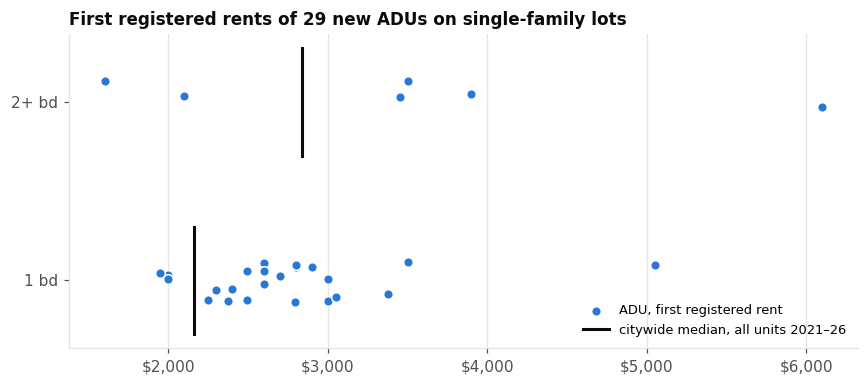

In [46]:
fig, ax = plt.subplots(figsize=(8, 3.6))
groups = [(label, br) for label, br in [("studio", 0), ("1 bd", 1), ("2+ bd", 2)]
          if adus.loc[adus["bedrooms"].clip(upper=2).eq(br), "first_rent"].notna().any()]
rng = np.random.default_rng(0)
for i, (label, br) in enumerate(groups):
    sel = adus[adus["bedrooms"].clip(upper=2).eq(br)].dropna(subset=["first_rent"])
    ax.scatter(sel["first_rent"], i + rng.uniform(-0.12, 0.12, len(sel)), s=40, color=SERIES[0],
               edgecolor="white", linewidth=1, zorder=3, label="ADU, first registered rent" if i == 1 else None)
    med = panel.loc[panel["year"].between(2021, 2026) & panel["bedrooms"].astype("float").clip(upper=2).eq(br), "rent_clean"].median()
    ax.plot([med, med], [i - 0.3, i + 0.3], color=INK, lw=2, zorder=2,
            label="citywide median, all units 2021–26" if i == 1 else None)
ax.set_yticks(range(len(groups)), [g[0] for g in groups])
ax.xaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_title(f"First registered rents of {adus['first_rent'].notna().sum()} new ADUs on single-family lots")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()

## 12. ADUs and property sales: built before or after the last reassessment?

**Data.** LA County Assessor multi-roll file `PostDoc/data/raw_la/parcels/AssessorParcelsData_MultRolls.db`, opened **read-only**. It holds one row per parcel per roll year, for rolls **2006–2024**, and the Culver City rows are pulled with a single query.

**Implied tax year = land base year.** Under Prop 13, land is reassessed only on a change of ownership. So a roll-to-roll change in `Roll_LandBaseYear` marks a sale. New construction, like an ADU, can move the *improvement* base year but not the land base year.

**Sale date.** This is the deed `RecordingDate` in the roll where the base year changes, which is available for 94% of changes. Otherwise it's Jan 1 of the base year. Deeds recorded July–December get the *next* year as their base year (fiscal-year convention), so the deed date is the more precise one. Sales are observed from 2006 through **Dec 2023**, the last change the 2024 roll can see.

**ADU completion comes from the permit final date, not the roll.** The roll rarely records the ADU as a new building or unit: only 21 of 259 completed ADU lots show one.

**Samples.** The single-family ADU lots completed by mid-2025 from section 11 are split into **ADU rented** (a registered ADU with a rent) and **ADU not registered as a rental**. Lots are linked to the roll by assessor parcel number (AIN).

In [47]:
ASSESSOR_DB = Path("/Users/adamswietek/Documents/PostDoc/data/raw_la/parcels/AssessorParcelsData_MultRolls.db")
con = sqlite3.connect(f"file:{ASSESSOR_DB}?mode=ro", uri=True)  # read-only
assessor_rolls = pd.read_sql(
    "select AIN, RollYear, UseCode, Units, totBuildingDataLines, SQFTmain, Bedrooms, Bathrooms, YearBuilt, RecordingDate, "
    "Roll_LandBaseYear, Roll_ImpBaseYear, Roll_LandValue, Roll_ImpValue, Roll_HomeOwnersExemp "
    "from parcels where TaxRateArea_CITY = 'CULVER CITY'", con)
con.close()
assessor_rolls = assessor_rolls.sort_values(["AIN", "RollYear"]).reset_index(drop=True)
assessor_rolls["deed_date"] = pd.to_datetime(assessor_rolls["RecordingDate"].astype("Int64").astype(str), format="%Y%m%d", errors="coerce")

by_ain = assessor_rolls.groupby("AIN")
prev_base, prev_deed = by_ain["Roll_LandBaseYear"].shift(), by_ain["deed_date"].shift()
reassessed = assessor_rolls["Roll_LandBaseYear"].ne(prev_base) & prev_base.notna() & assessor_rolls["Roll_LandBaseYear"].gt(1900)
parcel_sales = assessor_rolls.loc[reassessed, ["AIN", "RollYear", "Roll_LandBaseYear", "deed_date"]].copy()
deed_matches = parcel_sales["deed_date"].ne(prev_deed[reassessed]) \
    & (parcel_sales["deed_date"].dt.year - parcel_sales["Roll_LandBaseYear"]).between(-1, 0)
parcel_sales["sale_date"] = parcel_sales["deed_date"].where(
    deed_matches, pd.to_datetime(parcel_sales["Roll_LandBaseYear"].astype(str) + "-01-01"))
SALES_OBSERVED_TO = parcel_sales["sale_date"].max()

print(f"{len(assessor_rolls):,} parcel-years, {assessor_rolls['AIN'].nunique():,} parcels, rolls "
      f"{assessor_rolls['RollYear'].min()}–{assessor_rolls['RollYear'].max()}")
print(f"{len(parcel_sales):,} reassessments (land base-year changes) on {parcel_sales['AIN'].nunique():,} parcels; "
      f"dated by deed: {deed_matches.mean():.0%}; observed through {SALES_OBSERVED_TO:%Y-%m-%d}")

259,300 parcel-years, 14,177 parcels, rolls 2006–2024
10,361 reassessments (land base-year changes) on 6,597 parcels; dated by deed: 94%; observed through 2023-12-29


In [48]:
sale_dates = parcel_sales.groupby("AIN")["sale_date"].apply(sorted)
adu_sales = sf_lots[sf_lots["completed_by_mid_2025"]].copy()
adu_sales["AIN"] = pd.to_numeric(adu_sales["ain"], errors="coerce").astype("Int64")
adu_sales["sales"] = adu_sales["AIN"].map(sale_dates).apply(lambda v: v if isinstance(v, list) else [])
adu_sales["group"] = np.where(adu_sales["outcome"].eq("ADU registered"), "ADU rented", "ADU not registered as rental")

adu_sales["bought_before_permit"] = [max([d for d in s if d < o], default=pd.NaT) for s, o in zip(adu_sales["sales"], adu_sales["opened"])]
adu_sales["years_owned_at_permit"] = (adu_sales["opened"] - adu_sales["bought_before_permit"]).dt.days / 365.25
adu_sales["sold_during_construction"] = [any(o <= d <= f for d in s) for s, o, f in
                                         zip(adu_sales["sales"], adu_sales["opened"], adu_sales["final_date"])]
adu_sales["sold_after_final"] = [any(d > f for d in s) for s, f in zip(adu_sales["sales"], adu_sales["final_date"])]
adu_sales["post_final_window"] = (SALES_OBSERVED_TO - adu_sales["final_date"]).dt.days / 365.25
adu_sales["tenure_at_permit"] = pd.cut(adu_sales["years_owned_at_permit"].fillna(99), [-1, 2, 5, 10, 100],
                                       labels=["< 2 years", "2–5 years", "5–10 years", "10+ years (or no sale since 2006)"])

# baseline: single-family parcels with no ADU permit, over the 2 years before the same permit dates
sfd_ains = set(pd.to_numeric(parcels.loc[parcels["single_family"], "AIN"], errors="coerce").dropna().astype(int))
adu_ains = set(pd.to_numeric(sf_lots["ain"], errors="coerce").dropna().astype(int))
baseline = parcel_sales[parcel_sales["AIN"].isin(sfd_ains - adu_ains)]
baseline_recent = np.mean([
    baseline.loc[baseline["sale_date"].between(o - pd.DateOffset(years=2), o, inclusive="left"), "AIN"].nunique()
    / len(sfd_ains - adu_ains) for o in adu_sales["opened"]])


def share(mask, within=None):
    within = mask.index if within is None else within
    m = mask.loc[within]
    return f"{int(m.sum())} / {len(m)} ({m.mean():.0%})" if len(m) else "–"


long_window = adu_sales["post_final_window"] >= 1
rows = {
    "bought the house < 2 years before the ADU permit": lambda d: share(d["tenure_at_permit"].eq("< 2 years")),
    "bought 2–5 years before": lambda d: share(d["tenure_at_permit"].eq("2–5 years")),
    "bought 5–10 years before": lambda d: share(d["tenure_at_permit"].eq("5–10 years")),
    "owned 10+ years (or no sale since 2006)": lambda d: share(d["tenure_at_permit"].eq("10+ years (or no sale since 2006)")),
    "sold between permit and final": lambda d: share(d["sold_during_construction"]),
    "sold after final (ADUs finaled ≥ 1 yr before Dec 2023)": lambda d: share(d["sold_after_final"], d.index[long_window.loc[d.index]]),
    "homeowner's exemption (2023 roll)": lambda d: share(d["owner_occupied"].astype(bool)),
}
timing = pd.DataFrame({g: {k: f(d) for k, f in rows.items()} for g, d in
                       [("ADU rented", adu_sales[adu_sales["group"].eq("ADU rented")]),
                        ("ADU not registered as rental", adu_sales[adu_sales["group"].ne("ADU rented")]),
                        ("all completed single-family ADUs", adu_sales)]})
timing["single-family houses without an ADU permit (same dates)"] = ""
timing.loc["bought the house < 2 years before the ADU permit", "single-family houses without an ADU permit (same dates)"] = f"{baseline_recent:.0%}"
n_baseline = len(sfd_ains - adu_ains)
baseline_after = np.mean([
    baseline.loc[baseline["sale_date"].between(f, SALES_OBSERVED_TO, inclusive="right"), "AIN"].nunique() / n_baseline
    for f in adu_sales.loc[long_window, "final_date"]])
timing.loc["sold after final (ADUs finaled ≥ 1 yr before Dec 2023)", "single-family houses without an ADU permit (same dates)"] = f"{baseline_after:.0%}"
print("median years owned at permit:", adu_sales.groupby("group")["years_owned_at_permit"].median().round(1).to_dict())
timing

median years owned at permit: {'ADU not registered as rental': 2.3, 'ADU rented': 3.4}


,ADU rented,ADU not registered as rental,all completed single-family ADUs,single-family houses without an ADU permit (same dates)
bought the house < 2 years before the ADU permit,11 / 28 (39%),74 / 199 (37%),85 / 227 (37%),7%
bought 2–5 years before,2 / 28 (7%),24 / 199 (12%),26 / 227 (11%),
bought 5–10 years before,5 / 28 (18%),37 / 199 (19%),42 / 227 (19%),
owned 10+ years (or no sale since 2006),10 / 28 (36%),64 / 199 (32%),74 / 227 (33%),
sold between permit and final,3 / 28 (11%),14 / 199 (7%),17 / 227 (7%),
sold after final (ADUs finaled ≥ 1 yr before Dec 2023),3 / 14 (21%),12 / 79 (15%),15 / 93 (16%),6%
homeowner's exemption (2023 roll),14 / 28 (50%),89 / 199 (45%),103 / 227 (45%),


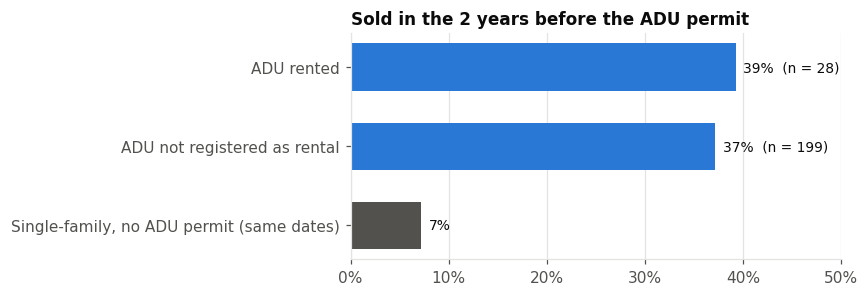

In [49]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = [
    ("Single-family, no ADU permit (same dates)", baseline_recent),
    ("ADU not registered as rental", adu_sales.loc[adu_sales["group"].ne("ADU rented"), "tenure_at_permit"].eq("< 2 years").mean()),
    ("ADU rented", adu_sales.loc[adu_sales["group"].eq("ADU rented"), "tenure_at_permit"].eq("< 2 years").mean()),
]
ns_ = [None, adu_sales["group"].ne("ADU rented").sum(), adu_sales["group"].eq("ADU rented").sum()]
for i, ((label, v), n) in enumerate(zip(bars, ns_)):
    ax.barh(i, v * 100, height=0.6, color=INK_2 if i == 0 else SERIES[0])
    ax.annotate(f"{v:.0%}" + (f"  (n = {n})" if n else ""), (v * 100, i), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(bars)), [b[0] for b in bars])
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlim(0, 50)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_title("Sold in the 2 years before the ADU permit")
fig.tight_layout()

## 13. ADUs, assessed value and sale prices

### How an ADU is assessed (background)
In California, building an ADU triggers a **partial (blended) assessment** of the new construction only:
- **Added value.** Once construction is finished, the assessor values the new ADU and adds that value to the property's existing base-year value. The whole property is *not* reset to market value.
- **Main house protected.** The house and land keep their original Prop 13 base year and the 2% annual cap on increases.
- **Tax impact.** The ADU's added value is taxed at the general 1% levy plus local voter-approved rates, roughly 1–1.25%. A $150,000 ADU adds about $1,500–1,900 a year.

**What the roll should show if this holds.** On ADU lots that don't sell during construction:
- the land and improvement **base years stay the same**;
- **land value grows only by the ~2% inflation factor**;
- the **improvement value jumps** by the ADU's assessed value once it is enrolled.

A **sale** instead resets the whole property to market value. That makes the reassessed value in the roll after a sale an **implied sale price**.

In [50]:
roll_by = assessor_rolls.set_index(["AIN", "RollYear"])
last_roll = assessor_rolls["RollYear"].max()
finished = sf_lots.dropna(subset=["final_date"]).copy()
finished["AIN"] = pd.to_numeric(finished["ain"], errors="coerce").astype("Int64")
finished = finished[finished["final_date"].dt.year < last_roll]

records = []
for ain, opened, final in zip(finished["AIN"], finished["opened"], finished["final_date"]):
    ain = int(ain)
    if (ain, opened.year) not in roll_by.index:
        continue
    before = roll_by.loc[(ain, opened.year)]  # lien date before the permit was opened
    for year in range(final.year + 1, last_roll + 1):
        if (ain, year) not in roll_by.index:
            break
        after = roll_by.loc[(ain, year)]
        records.append({
            "AIN": ain, "final_year": final.year, "years_since_final": year - final.year,
            "sold": after["Roll_LandBaseYear"] != before["Roll_LandBaseYear"],
            "imp_base_year_kept": after["Roll_ImpBaseYear"] == before["Roll_ImpBaseYear"],
            "land_vs_cap": after["Roll_LandValue"] / (before["Roll_LandValue"] * 1.02 ** (year - opened.year)),
            "added_imp_value": after["Roll_ImpValue"] - before["Roll_ImpValue"] * 1.02 ** (year - opened.year),
        })
adu_assessment = pd.DataFrame(records)
kept = adu_assessment.groupby("AIN").filter(lambda g: not g["sold"].any())  # lots never sold since the permit
latest = kept.sort_values("years_since_final").groupby("AIN").last()
enrolled = latest["added_imp_value"].gt(20_000)

print(f"finished single-family ADUs (finaled before the {last_roll} roll): {finished['AIN'].nunique()} | "
      f"sold since the permit (whole property reassessed): {adu_assessment.groupby('AIN')['sold'].any().sum()} | not sold: {len(latest)}")
print(f"not sold: improvement base year unchanged {latest['imp_base_year_kept'].mean():.0%} | "
      f"land value / 2%-capped value: median {latest['land_vs_cap'].median():.3f}")
display(kept.assign(enrolled=kept["added_imp_value"].gt(20_000))
        .pivot_table(index="final_year", columns="years_since_final", values="enrolled", aggfunc="mean")
        .style.format("{:.0%}", na_rep="–").set_caption("share of ADU lots whose roll shows > $20k added improvement value, by years since final"))
print(f"enrolled by the {last_roll} roll: {enrolled.sum()} of {len(latest)} ({enrolled.mean():.0%}); added value when enrolled: "
      f"median ${latest.loc[enrolled, 'added_imp_value'].median():,.0f} "
      f"(IQR ${latest.loc[enrolled, 'added_imp_value'].quantile(0.25):,.0f}–${latest.loc[enrolled, 'added_imp_value'].quantile(0.75):,.0f}) "
      f"-> about ${0.01 * latest.loc[enrolled, 'added_imp_value'].median():,.0f}–${0.0125 * latest.loc[enrolled, 'added_imp_value'].median():,.0f} a year in tax at 1–1.25%")

finished single-family ADUs (finaled before the 2024 roll): 141 | sold since the permit (whole property reassessed): 47 | not sold: 94
not sold: improvement base year unchanged 99% | land value / 2%-capped value: median 1.000


years_since_final,1,2,3
final_year,,,
2021,11%,18%,21%
2022,9%,28%,–
2023,12%,–,–


enrolled by the 2024 roll: 19 of 94 (20%); added value when enrolled: median $143,755 (IQR $78,385–$188,567) -> about $1,438–$1,797 a year in tax at 1–1.25%


**Reading this.**
- **Protection of the main house is confirmed.** On ADU lots that weren't sold, the house keeps its base year and the land value stays on the 2% path.
- **Enrolment lags.** Only about a fifth of finished ADUs show up on the regular roll within 1–3 years. The ADU is usually billed first through **supplemental assessments**, which this roll file doesn't contain. So the enrolled share is a lower bound on how many ADUs are assessed.
- **Added value when enrolled.** A median of about **$144k**, which matches the $150k example above.

### Implied sale prices: do houses with an ADU sell for more?

**Implied price.** The total assessed value (land + improvements) in the first roll after a reassessment is used as the sale price. It is deflated by 2% for each roll year past the base year. Only single-family detached parcels sold 2012–2023 are kept, and prices outside 0.4–3× that year's median are dropped as likely non-market transfers.

**Comparison.** A regression on log price, controlling for house size (log sq ft), bedrooms, bathrooms, decade built and sale year, and comparing within **assessor map book** or the finer **map page**. Standard errors are clustered by map page. Each sale is classed by its lot's ADU permit status at the time of sale:
- **ADU finished**: the ADU permit was finaled before the sale.
- **ADU under way**: the permit was opened but not yet finaled.
- **ADU within 3 yrs after purchase**: the sale was a purchase, followed within 3 years by an ADU permit. This tests whether ADU builders bought cheap or expensive houses.
- **no ADU permit**: everything else.

In [51]:
import statsmodels.formula.api as smf

sale_prices = parcel_sales.join(assessor_rolls[["Roll_LandValue", "Roll_ImpValue", "SQFTmain", "Bedrooms", "Bathrooms", "YearBuilt"]])
sale_prices["price"] = (sale_prices["Roll_LandValue"] + sale_prices["Roll_ImpValue"]) \
    / 1.02 ** (sale_prices["RollYear"] - sale_prices["Roll_LandBaseYear"]).clip(lower=0)
sale_prices["sale_year"] = sale_prices["sale_date"].dt.year
sale_prices = sale_prices[sale_prices["AIN"].isin(sfd_ains) & sale_prices["sale_year"].between(2012, 2023)
                          & sale_prices["SQFTmain"].gt(300) & sale_prices["YearBuilt"].gt(1880)]
sale_prices = sale_prices[(sale_prices["price"] / sale_prices.groupby("sale_year")["price"].transform("median")).between(0.4, 3)]

adu_dates = sf_lots.assign(AIN=pd.to_numeric(sf_lots["ain"], errors="coerce")).dropna(subset=["AIN"]) \
    .astype({"AIN": int})[["AIN", "opened", "final_date"]]
sale_prices = sale_prices.merge(adu_dates, on="AIN", how="left")
finished_at_sale = sale_prices["final_date"].lt(sale_prices["sale_date"])
sale_prices["adu_status"] = np.select(
    [finished_at_sale,
     sale_prices["opened"].le(sale_prices["sale_date"]),
     sale_prices["opened"].gt(sale_prices["sale_date"]) & (sale_prices["opened"] - sale_prices["sale_date"]).dt.days.le(3 * 365)],
    ["ADU finished", "ADU under way", "ADU within 3 yrs after purchase"],
    default="no ADU permit",
)
sale_prices = sale_prices.assign(
    log_price=np.log(sale_prices["price"]), log_sqft=np.log(sale_prices["SQFTmain"]),
    beds=sale_prices["Bedrooms"].clip(upper=6), baths=sale_prices["Bathrooms"].clip(upper=5),
    decade=(sale_prices["YearBuilt"] // 10 * 10).clip(lower=1910),
    map_book=sale_prices["AIN"] // 1_000_000, map_page=sale_prices["AIN"] // 1_000,
)

ADU_STATUSES = ["ADU finished", "ADU under way", "ADU within 3 yrs after purchase"]
hedonic, fits = [], {}
for fe in ["map_book", "map_page"]:
    fit = smf.ols(f"log_price ~ C(adu_status, Treatment('no ADU permit')) + log_sqft + C(beds) + C(baths) + C(decade) "
                  f"+ C(sale_year) + C({fe})", data=sale_prices).fit(cov_type="cluster", cov_kwds={"groups": sale_prices["map_page"]})
    fits[fe] = fit
    for status in ADU_STATUSES:
        term = f"C(adu_status, Treatment('no ADU permit'))[T.{status}]"
        b, se = fit.params[term], fit.bse[term]
        hedonic.append({"comparison within": fe.replace("_", " "), "ADU status at sale": status,
                        "sales": int(sale_prices["adu_status"].eq(status).sum()),
                        "price vs similar homes": np.exp(b) - 1, "95% CI low": np.exp(b - 1.96 * se) - 1,
                        "95% CI high": np.exp(b + 1.96 * se) - 1, "R²": fit.rsquared})
hedonic = pd.DataFrame(hedonic).set_index(["comparison within", "ADU status at sale"])
print(f"{len(sale_prices):,} single-family sales 2012–2023: {sale_prices['adu_status'].value_counts().to_dict()}")
hedonic.style.format({"sales": "{:,.0f}", "price vs similar homes": "{:+.0%}", "95% CI low": "{:+.0%}", "95% CI high": "{:+.0%}", "R²": "{:.2f}"})

2,903 single-family sales 2012–2023: {'no ADU permit': 2711, 'ADU within 3 yrs after purchase': 148, 'ADU under way': 24, 'ADU finished': 20}


### Most ADU-then-sale transactions are flips

This takes each sale of a house with a finished ADU and, where there is one, its purchase before the ADU permit. The gain is compared with the citywide single-family market over the same period: the quarterly median implied price, smoothed over four quarters. It also counts the other permits pulled on the lot between purchase and sale.

In [52]:
sfd_sales = parcel_sales.join(assessor_rolls[["Roll_LandValue", "Roll_ImpValue"]])
sfd_sales = sfd_sales[sfd_sales["AIN"].isin(sfd_ains)].assign(
    price=lambda d: (d["Roll_LandValue"] + d["Roll_ImpValue"]) / 1.02 ** (d["RollYear"] - d["Roll_LandBaseYear"]).clip(lower=0))
market = sfd_sales.groupby(sfd_sales["sale_date"].dt.to_period("Q"))["price"].median().rolling(4, center=True, min_periods=2).median()
OTHER_SCOPES = ["kitchen_remodel", "roof_replacement", "panel_upgrade", "hvac", "foundation", "seismic"]

flip_rows = []
for sale in sale_prices[sale_prices["adu_status"].eq("ADU finished")].itertuples():
    lot = sf_lots[pd.to_numeric(sf_lots["ain"], errors="coerce").eq(sale.AIN)].iloc[0]
    bought = sfd_sales[sfd_sales["AIN"].eq(sale.AIN) & sfd_sales["sale_date"].lt(lot["opened"])].sort_values("sale_date").tail(1)
    since = bought["sale_date"].iloc[0] if len(bought) else lot["opened"] - pd.DateOffset(years=2)
    work = permits[permits["key"].eq(lot["key"]) & permits["date"].between(since, sale.sale_date)]
    row = {"AIN": sale.AIN, "ADU final": lot["final_date"], "sold": sale.sale_date, "sale price": sale.price,
           "permits between": len(work),
           "other work": ", ".join(s for s in OTHER_SCOPES if work[s].any()) +
                         (" + remodel/addition" if work["work_description"].fillna("").str.upper().str.contains("ADDITION|REMODEL").any() else "")}
    if len(bought):
        b = bought.iloc[0]
        row.update({"bought": b["sale_date"], "purchase price": b["price"],
                    "months held": (sale.sale_date - b["sale_date"]).days / 30.4,
                    "gain": sale.price / b["price"] - 1,
                    "market gain": market[sale.sale_date.to_period("Q")] / market[b["sale_date"].to_period("Q")] - 1})
    flip_rows.append(row)
flips = pd.DataFrame(flip_rows).sort_values("sold")
flips["gain above market"] = (1 + flips["gain"]) / (1 + flips["market gain"]) - 1
with_purchase = flips.dropna(subset=["gain"])
print(f"{len(flips)} sales after an ADU was finished; {len(with_purchase)} with the pre-ADU purchase observed: "
      f"median {with_purchase['months held'].median():.0f} months held, gain {with_purchase['gain'].median():+.0%} vs market "
      f"{with_purchase['market gain'].median():+.0%} (median gain above market {with_purchase['gain above market'].median():+.0%}, "
      f"${(with_purchase['sale price'] - with_purchase['purchase price']).median():,.0f}); "
      f"sold within 3 months of the ADU final: {((flips['sold'] - flips['ADU final']).dt.days <= 92).mean():.0%}")
flips.style.format({"sale price": "${:,.0f}", "purchase price": "${:,.0f}", "months held": "{:.0f}", "gain": "{:+.0%}",
                    "market gain": "{:+.0%}", "gain above market": "{:+.0%}", "ADU final": "{:%Y-%m-%d}",
                    "sold": "{:%Y-%m-%d}", "bought": "{:%Y-%m-%d}"}, na_rep="–").hide(axis="index")

20 sales after an ADU was finished; 15 with the pre-ADU purchase observed: median 30 months held, gain +100% vs market +17% (median gain above market +76%, $1,445,000); sold within 3 months of the ADU final: 60%


AIN,ADU final,sold,sale price,permits between,other work,bought,purchase price,months held,gain,market gain,gain above market
4203009026,2021-04-16,2021-05-06,"$2,200,000",4,+ remodel/addition,–,–,–,–,–,–
4207026025,2021-05-06,2021-07-20,"$3,200,000",4,,2018-06-07,"$1,400,000",37,+129%,+18%,+94%
4208025030,2021-01-04,2021-07-29,"$1,725,000",5,,2019-08-29,"$1,114,786",23,+55%,+13%,+37%
4206009024,2021-03-03,2021-09-03,"$2,600,000",11,hvac,2019-02-21,"$1,150,000",30,+126%,+18%,+91%
4231023011,2022-01-07,2022-01-27,"$3,400,000",9,,2019-09-10,"$1,250,000",29,+172%,+21%,+125%
4213008015,2021-12-21,2022-03-15,"$2,400,024",4,,2018-07-09,"$1,225,000",44,+96%,+26%,+55%
4209015014,2021-09-21,2022-04-07,"$1,500,000",5,,2015-08-14,"$1,350,000",80,+11%,+66%,-33%
4203010024,2022-06-16,2022-06-28,"$2,149,000",8,,–,–,–,–,–,–
4209025012,2021-04-05,2022-08-18,"$3,000,000",4,+ remodel/addition,2007-10-05,"$776,000",179,+287%,+120%,+76%
4205016017,2022-08-24,2022-10-12,"$3,000,000",11,foundation,–,–,–,–,–,–


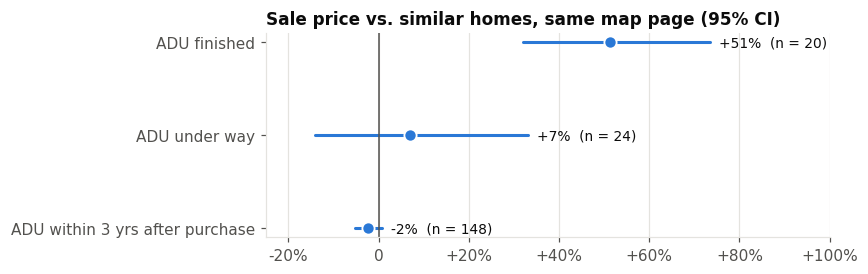

In [53]:
h = hedonic.loc["map page"]
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (status, row) in enumerate(h.iterrows()):
    ax.plot([row["95% CI low"] * 100, row["95% CI high"] * 100], [i, i], color=SERIES[0], lw=2, solid_capstyle="round")
    ax.plot(row["price vs similar homes"] * 100, i, "o", ms=8, color=SERIES[0], markeredgecolor="white", markeredgewidth=1.2)
    ax.annotate(f"{row['price vs similar homes']:+.0%}  (n = {int(row['sales'])})", (row["95% CI high"] * 100, i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(range(len(h)), h.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%" if v else "0")
ax.set_xlim(-25, 100)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_title("Sale price vs. similar homes, same map page (95% CI)")
fig.tight_layout()

**Reading this.**
- **Buyers who then build an ADU paid about market prices.** There's no premium or discount for "ADU-able" lots (about 0%).
- **Houses sold after an ADU was finished went for about 50% more than comparable houses.** But most of these sales are value-add flips: bought a median ~2½ years earlier, many other permits in between, often a remodel or addition, and frequently sold within weeks of the ADU final.
- **So +50% is the premium for "ADU plus renovation", an upper bound for the ADU alone.** The roll's size and bedroom counts often don't reflect the remodel either. For scale, the assessor's own valuation of a median ADU (~$144k) is about 6–7% of these sale prices.
- **Separating the ADU would need** the remodel scope from permit descriptions, or post-ADU sales that aren't flips. There are only ~20 such sales so far, and sales in 2024 and later need a newer roll.

## Takeaways & data-quality notes

- **Culver City extent.** 8 years (2019–2026) and ~48k rent records covering ~8.4k units at ~2.9k addresses (~2.5k buildings) held by ~2.8k owners. Another ~1.1k registered addresses have no rent records.
- **Beverly Hills snapshot.** After excluding 3 explicit test rows and one exact duplicate, the report contains 7,458 unit rows at 2,332 addresses and 1,091 APNs, with 6,307 usable current rents. It is a current snapshot, not a rent-history panel; 1,106 rows lack monthly rent and many lack bedroom counts.
- **Frequency.** In effect this is an annual panel: one registration per unit per year, in June–July. Only ~870 units appear in all 8 years.
- **Uneven coverage.** 2019, the base-rent year, has the most units. Coverage drops sharply in 2020–2021 (2021 has about a quarter of the units), recovers from 2022, and stays at ~6.4k units per year for 2024–2026. Treat 2020–21 with care.
- **2022 has two rent dates** for many units (1/1/2022 plus the mid-year registration).
- **Duplicate registration blocks** exist for ~380 addresses. The dedupe keeps the most current block. The blocks can use different unit-numbering schemes (e.g. *6220 Bristol Pkwy*), which would inflate the unit counts for those addresses.
- **The rent-control flag changed between releases.** Use the 26-962 value.
- **Owner names are not standardized.** Some `owner_name` values look like property managers or agents rather than owners (individuals listed on 90+ units). Entity resolution (trusts, LLCs, trustees, managers) is needed before any ownership analysis.

- **Same-unit histories.** 7,849 units have usable rents in 2 or more years. That gives ~27k consecutive-year same-unit pairs across ~7.2k units and ~2.5k addresses. Gapped pairs add ~6.4k more.
- **Year-over-year changes.** In a typical year about half of units show no change, ~48% an increase and ~6% a decrease. Increases cluster at exact percentages (3.0, 3.2, 3.3, 3.5, 4.0, 5.0%), which points to capped allowable increases. The median increase peaked at 5.0% in 2022→23 and settled at ~3.25% in 2024→26. The 2020→21 year is unusual: only 18% of units went up and 9% went down.
- **Cumulative growth, 2019→2026.** A unit's rent grew ~14% (~11% for continuing tenants), while the cross-sectional median rose ~25%. Turnover and changes in which units report account for a large share of the headline growth.
- **The rent-control flag barely separates the groups.** Rent-controlled and other units have nearly identical median increases from 2022→23 on. Check what the flag actually encodes before relying on it.
- **Tenure samples (section 7).** These are built from lease-start dates across both releases, not from rents.
  - **Long-term-tenant buildings:** 372 buildings with 609 units. At least 80% of units have had the same tenant since before June 2019 (median 12 years in place).
  - **High-turnover buildings:** 1,130 buildings with 2,720 units. At least 80% of units had a move-in or a vacancy during the sample.
  - **Large buildings** almost all land in *mixed*.
  - **Rents, which were not used to build the samples, confirm the split.** Compared with high-turnover buildings, long-term buildings have more years with no change (57% vs 46%), fewer decreases (3% vs 6%) and fewer jumps above 10% (4.5% vs 7.7%). Their cumulative growth is also lower (index 112 vs 116).
- **The two samples differ in composition too.** The long-term sample is mostly single-unit properties with cheaper rents (2019 median $1,975 vs $2,450). Compare the samples within size groups.
- **Ownership changes (section 8).** 110 owner changes at 105 properties, found by comparing consecutive registrations of the same address. That excludes 221 name differences that are the same owner written differently. 65 sales are dated to within one registration cycle.
  - **Before the sale**, rents at sold properties track the same-year average at unsold properties (about +0.1 pt).
  - **At the sale and after**, increases run 1–2 pts per year higher, and increases above 10% become more common. The confidence bands include zero, because only ~60 properties are involved.
  - **For better sale dates**, 82% of sold addresses have a parcel number (APN) that could be linked to LA County Assessor transfer records.
- **Permit overlap (section 9).** The two Culver City permit sources combine to 22.9k permits, mostly 2020–2026, and 7.8k of them are at registry properties.
  - **Permits are matched by normalized address**, with parcel number as a fallback. The two methods agree 97% of the time.
  - **47% of rental properties had at least one permit in 2019–2026.** Those properties hold 60% of registered units. For buildings with 5 or more units the share rises to ~65%, and about a third of those buildings are in the soft-story retrofit program.
  - **Coverage before 2020 is thin**: only ~500 permits in the feed for 2019.
- **Major permits (section 10).** The contractor-search vocabulary was re-applied to 2019–26 permits and agrees 99% with the app's own matches. 581 rental properties had a major permit.
  - **No permit group is followed by a lasting rent increase** compared with properties that had no major permit.
  - **Kitchen remodels show a one-registration bump** right after the permit (+1.7 ± 0.9 pt). HVAC (+2.1 ± 1.8) and panel upgrades (+0.9 ± 0.6) show the same pattern, more noisily. The bump doesn't last, and sitting tenants see little of it.
  - **Seismic retrofits show no pass-through to rents.**
  - **ADU properties run ~1 pt below the comparison group both before and after the permit.** That points to a difference in which properties add ADUs, not an effect of the ADU.
  - **These effects are diluted**, because permits are assigned to whole properties.
- **Single-family ADUs (section 11).** Single-family lots are identified with the LA County assessor's use codes. Of the 227 ADUs on those lots completed by mid-2025:
  - **28 (12%) show a registered ADU rent.** When they do, it arrives a median ~3 months after completion.
  - **1-bedroom ADUs rent for a median $2,600**, about 1.2× the citywide 1-bedroom median in the same year.
  - **22 lots are registered but declare no rental unit, and 164 (72%) aren't in the registry at all.** The share doesn't rise for ADUs completed earlier, so it isn't registration lag. Most ADUs either aren't rented or are rented without being registered.
- **ADUs and sales (section 12).** Sales are identified from land base-year changes in the 2006–2024 assessor rolls.
  - **ADUs are mostly built right after a purchase.** 37% of completed single-family ADU lots sold in the 2 years before the ADU permit, compared with 7% of other single-family houses over the same dates.
  - **ADU lots also resell more often.** 16% sold after the ADU was finished, compared with 6% of other houses over the same windows.
  - **Rented ADUs look like the rest.** 39% bought within 2 years (vs 37%) and 21% sold after completion (vs 15%). Only 28 ADUs are rented, though.
- **ADU assessment and sale prices (section 13).**
  - **The assessment rules check out on the roll.** On ADU lots that weren't sold, the house keeps its base year (99%) and land grows at the 2% cap. An ADU's added value appears on the regular roll for only ~20% of lots within 1–3 years, since billing starts through supplemental assessments. When it does appear, the median is ~$144k, about $1,400–1,800 a year in tax.
  - **Buyers who then build an ADU pay about market prices** (−2% to 0% vs similar homes).
  - **Houses sold after an ADU was finished go for ~50% more than comparable homes** (95% CI +32% to +73%, n = 20). But most are flips: held a median 30 months, resold at +100% vs +17% for the market, 60% sold within 3 months of the ADU final, often with remodels. So this is the premium for "ADU plus renovation", not for the ADU alone.

Cleaned objects in memory: `bh` (Beverly Hills 2026 unit snapshot), `df` (full Culver City rent panel), `panel` (Culver City 2019–2026), `units` / `cc_units` (latest Culver City row per unit), `no_rent` (Culver City registrations with no rent records), `unit_year` (one rent per unit-year), `yoy` (consecutive-year same-unit changes), `tenure` (one row per unit: move-ins and tenure class), `buildings` (one row per building: shares and `sample`), `sales` (one row per owner change, with its date window), `permits` (one row per permit, with matched property `prop`), `rental_props` (one row per rental property: units, permit count, sample), `first_permit` (first major permit date per property, by group), `events` (event-time pairs by group), `parcels` (Culver City assessor parcels), `sf_lots` / `adus` (single-family ADU lots and the ADUs found in the registry), `parcel_sales` (reassessment-dated sales, 2006–2023), `adu_sales` (sale timing per completed ADU lot), `adu_assessment` (roll values around ADU completion), `sale_prices` / `hedonic` (implied prices and the comparison), `flips` (post-ADU resales).